# Introduction

This notebook provides a novel approach to building a machine learning model for predicting the outcome of credit card default. This approach began with exploring the data, which involved analysing both continuous and categorical features, identifying undefined values in the dataset, and testing for multicollinearity. The next step taken was data transformation. Here, undefined values were reassigned, and outliers were detected and removed. Feature engineering was then carried out in an effort to reduce extreme cases of multicollinearity and derive greater relationships between features for greater interpretation of the dataset. 

Model training and evaluation was implemented for logistic regression, random forest, and Extreme Gradient Boosting (XGB). Before training the models, Synthetic Minority Oversampling Technique (SMOTE) was implemented, as the training dataset was imbalanced. Stratified k-fold cross validation was used to train the models, and hyperparameters were tuned for each model. The models were assessed using learning curves, precision-recall (PR) curves, confusion matrices, and classification reports. Upon carrying out model evaluation and assessment, it was found that the logistic regression model performed the best, and hence was the learning model of choice. Feature selection was applied, and the logistic regression model was then re-trained. The logistic regression model was then applied to the test dataset, to give a precision score of 0.88 and 0.50, a recall score of 0.85 and 0.56, and an f1-score of 0.86 and 0.53 for the non-default and default classes respectively.

# Runtime

- ~ 8 to 10 minutes with the 3 learning curve plots combined cell
- ~ 5 to 7 minutes  with the 3 learning curve plots combined cell commented out

# Imports

## Library Imports

Libraries utilised include Pandas, Matplotlib, Numpy, Seaborn, Xgboost, Imblearn, Statsmodels, and Sklearn

In [1]:
import pandas as pd

import numpy as np

import seaborn as sns

import matplotlib.pyplot as plt

from xgboost import XGBClassifier

from statsmodels.stats.outliers_influence import variance_inflation_factor

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.model_selection import train_test_split, learning_curve, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.neighbors import LocalOutlierFactor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, auc, precision_recall_curve

## Data Imports

In [2]:
# working directory
wd = 'C:/Users/yspat/University - Minor/Project/'

# train location
train_loc = wd + 'CreditCard_train.csv'
# test location
test_loc = wd + 'CreditCard_test.csv'

# train data
data = pd.read_csv(train_loc, header=1)
# test data
test_data = pd.read_csv(test_loc, header=1)

# Glancing the Train Data

In [3]:
data.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [4]:
data.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
count,24000.000000,24000.000000,24000.000000,24000.000000,24000.00000,24000.000000,24000.000000,24000.00000,24000.000000,24000.000000,...,24000.000000,24000.000000,24000.000000,24000.000000,2.400000e+04,24000.00000,24000.000000,24000.000000,24000.000000,24000.000000
mean,12000.500000,165495.986667,1.628250,1.847417,1.55725,35.380458,-0.003125,-0.12350,-0.154750,-0.211667,...,42368.188417,40000.682542,38563.710625,5542.912917,5.815336e+03,4969.26600,4743.480042,4783.486042,5189.399042,0.223750
std,6928.347566,129128.744855,0.483282,0.780007,0.52208,9.271050,1.123425,1.20058,1.204033,1.166549,...,63070.680934,60345.012766,59155.759799,15068.576072,2.079703e+04,16095.61434,14883.269990,15270.405279,17630.371990,0.416765
min,1.000000,10000.000000,1.000000,0.000000,0.00000,21.000000,-2.000000,-2.00000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,6000.750000,50000.000000,1.000000,1.000000,1.00000,28.000000,-1.000000,-1.00000,-1.000000,-1.000000,...,2340.000000,1740.000000,1234.750000,1000.000000,8.000000e+02,379.00000,279.750000,244.000000,60.750000,0.000000
50%,12000.500000,140000.000000,2.000000,2.000000,2.00000,34.000000,0.000000,0.00000,0.000000,0.000000,...,18940.500000,18107.500000,17036.000000,2100.000000,2.000000e+03,1702.50000,1500.000000,1500.000000,1500.000000,0.000000
75%,18000.250000,240000.000000,2.000000,2.000000,2.00000,41.000000,0.000000,0.00000,0.000000,0.000000,...,52188.500000,49746.500000,48796.250000,5000.000000,5.000000e+03,4347.25000,4000.000000,4005.000000,4000.000000,0.000000
max,24000.000000,1000000.000000,2.000000,6.000000,3.00000,79.000000,8.000000,8.00000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,505000.000000,1.684259e+06,896040.00000,497000.000000,417990.000000,528666.000000,1.000000


Initial observations:
- There appears to be values in the PAY_#, EDUCATION and MARRIAGE columns which have not been defined, these will be investigated later on
- The PAY_0 column heading seems strange and the default payment next month column name is rather long
- The BILL_AMT# columns have negative values

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24000 entries, 0 to 23999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          24000 non-null  int64
 1   LIMIT_BAL                   24000 non-null  int64
 2   SEX                         24000 non-null  int64
 3   EDUCATION                   24000 non-null  int64
 4   MARRIAGE                    24000 non-null  int64
 5   AGE                         24000 non-null  int64
 6   PAY_0                       24000 non-null  int64
 7   PAY_2                       24000 non-null  int64
 8   PAY_3                       24000 non-null  int64
 9   PAY_4                       24000 non-null  int64
 10  PAY_5                       24000 non-null  int64
 11  PAY_6                       24000 non-null  int64
 12  BILL_AMT1                   24000 non-null  int64
 13  BILL_AMT2                   24000 non-null  int64
 14  BILL_A

- No NaNs are present in the dataset
- All data are of the type: int64

# Exploratory Analysis

## Heatmap Overview

<AxesSubplot:>

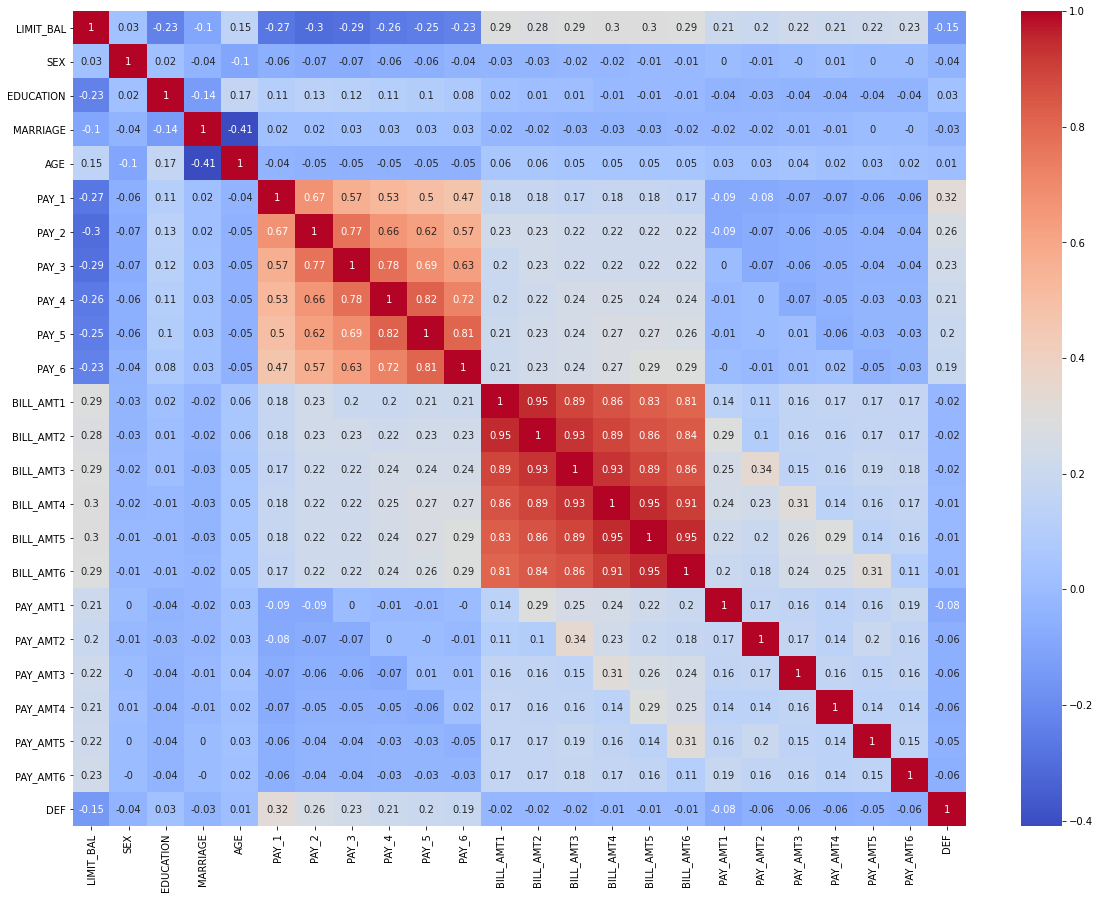

In [6]:
# Reassigning default column name, as the current name is rather long
data.rename(columns={'default payment next month':'DEF'}, inplace=True)

# renaming PAY_0 to PAY_1
# repayment status in September (X6) is inconsistent with the succeeding 5 pay columns, 
# since X6 is named Pay_0, while columns X7-X11 were numbered from Pay_2 to Pay_6. As such, Pay_0 will be renamed to Pay_1
data.rename(columns={'PAY_0':'PAY_1'}, inplace=True)

# heatmap plot utilising Pearson's correlation
plt.figure(figsize=(20,15))
sns.heatmap(data.drop('ID', axis=1).corr().round(2), cmap='coolwarm', annot=True)

- PAY_# appear to be highly correlated with each other

- BILL_AMT# appear to be highly correlated with each other

- LIMIT_BAL and PAY_# appear to have a higher correlation to DEF compared to the other columns

## Distribution of Catergorical Features 

### SEX, MARRIAGE, EDUCATION, DEFAULT

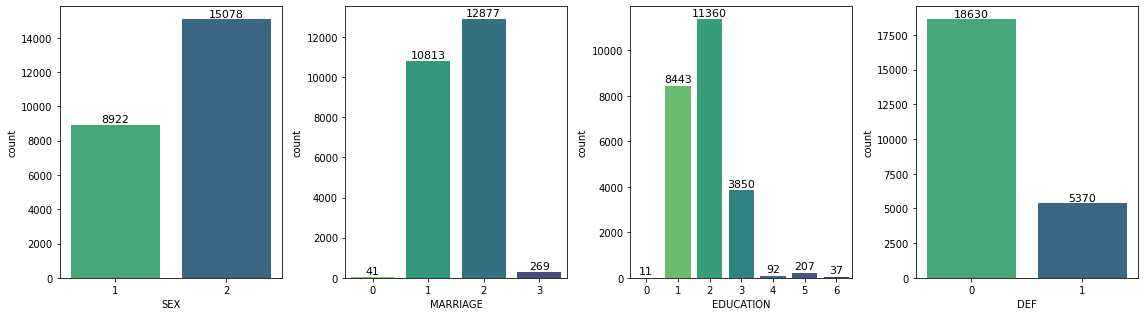

In [7]:
# bar plots
figure, axs = plt.subplots(nrows=1, ncols=4, figsize=(16,4.5))

SMED = zip(['SEX', 'MARRIAGE', 'EDUCATION', 'DEF'],[0,1,2,3])

for item, x in SMED:
    pay = sns.countplot(data=data, x=item, ax=axs[x], palette='viridis_r')
    for rect in pay.patches:
        pay.text((rect.get_x() + rect.get_width()/2), (rect.get_height()+150),
                  rect.get_height(), horizontalalignment='center', fontsize=11)
plt.tight_layout()

The dataset appears to be imbalanced as there are far more non-defaulters than defaulters

Events per variable, to ensure we have enough observations per smallest predictor

In [8]:
# EPV
minimum = min(data[data['DEF']==1].shape[0], data[data['DEF']==1].shape[0])

round((minimum/23),2)

233.48

Dealing with the undefined values for EDUCATION and AGE:

In [9]:
# assigning education values 0, 5 and 6 to 4 (other catergory)
data['EDUCATION'].replace({0:4, 5:4, 6:4}, inplace=True)

# assigning the 0 in marraige to 3 (other catergory)
data['MARRIAGE'].replace({0:3}, inplace=True)

### PAY_#

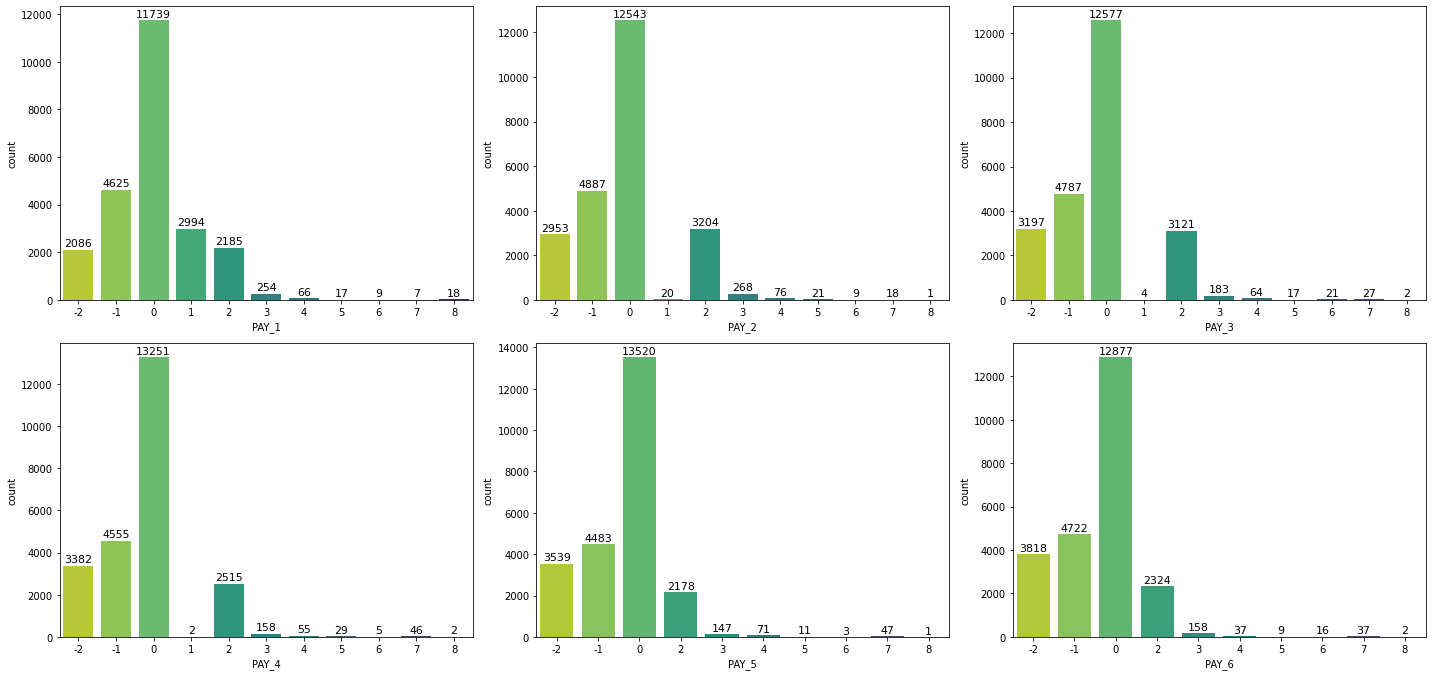

In [10]:
# bar plots
figure, axs = plt.subplots(nrows=2, ncols=3, figsize=(20,9.5))

layout = [(0,0,'PAY_1'), (0,1,'PAY_2'), (0,2,'PAY_3'), (1,0,'PAY_4'), (1,1,'PAY_5'), (1,2,'PAY_6')]

for x,y,item in layout:
    pay = sns.countplot(data=data, x=item, ax=axs[x,y], palette='viridis_r')
    for rect in pay.patches:
        pay.text (rect.get_x() + rect.get_width()  / 2,rect.get_height()+ 150,
                  rect.get_height(),horizontalalignment='center', fontsize = 11)
plt.tight_layout()

Dealing with the undefined values for PAY_#:

In [11]:
# The -2 and 0 values are not assigned 
# Research has indicated that 0 = revolving credit and -2 = no consumption
# -2, -1 and 0 indicate payments are made on time and can thus be assigned to 0 as we are only concerned as to whether or not
# people pay on time

for i in ['PAY_1','PAY_2','PAY_3','PAY_4','PAY_5', 'PAY_6']:
    data.replace({i:{-2:0, -1:0}}, inplace=True)

Summary of PAY_# via a heatmap and boxenplot:

<AxesSubplot:>

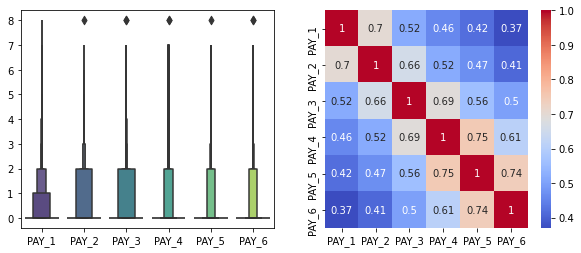

In [12]:
figure, axs = plt.subplots(nrows=1, ncols=2, figsize=(10,4))
# boxenplot
sns.boxenplot(data=data[['PAY_1','PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']], ax=axs[0], palette='viridis')
# heatmap
sns.heatmap(data=data[['PAY_1','PAY_2','PAY_3','PAY_4','PAY_5', 'PAY_6']].corr().round(2), annot=True, cmap='coolwarm', 
            ax=axs[1])

- The distribution of values in PAY_2 and PAY_3 are similar
- The distribution of values in PAY_4, PAY_5 and PAY_6 are similar
- The PAY_# are highly correlated with one another

## Distribution of Continous Features

### LIMIT_BAL and AGE

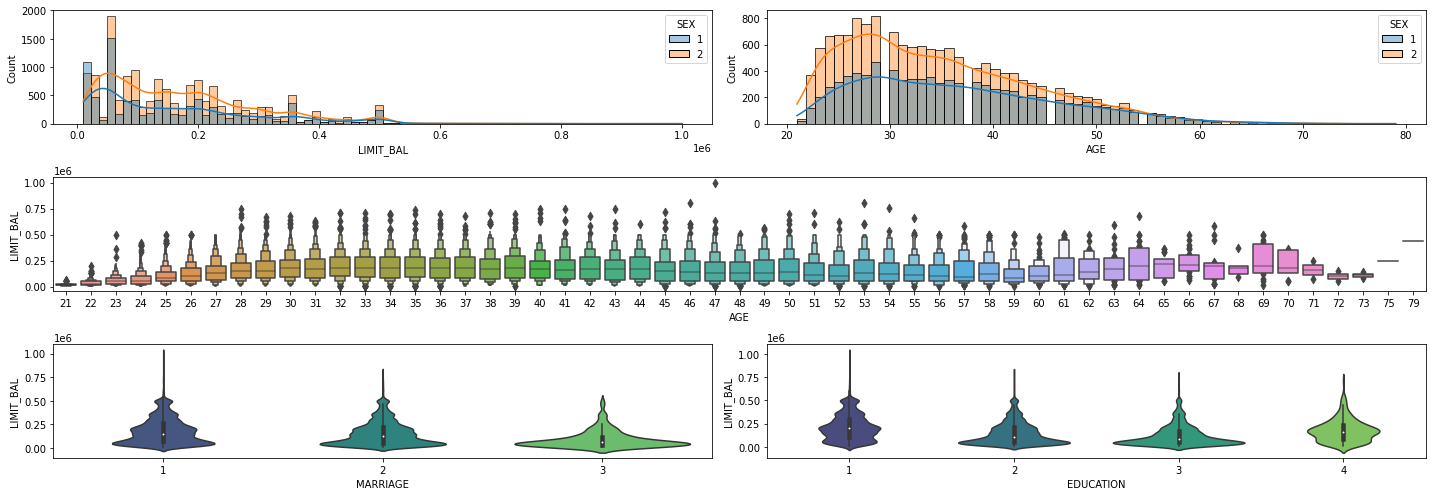

In [13]:
# figure setup
plt.figure(figsize=(20,7))
ax1 = plt.subplot2grid(shape=(3, 2), loc=(0, 0), colspan=1)
ax2 = plt.subplot2grid(shape=(3, 2), loc=(0, 1), colspan=1)
ax3 = plt.subplot2grid(shape=(3, 2), loc=(1, 0), colspan=2)
ax4 = plt.subplot2grid(shape=(3, 2), loc=(2, 0), colspan=1)
ax5 = plt.subplot2grid(shape=(3, 2), loc=(2, 1), colspan=1)

# limit_bal histogram with hue=sex plot
sns.histplot(data=data, x='LIMIT_BAL', kde=True, palette='tab10',alpha=0.4, hue='SEX', ax=ax1)
# age histogram with hue=sex plot
sns.histplot(data=data, x='AGE', kde=True, palette='tab10',alpha=0.4, hue='SEX', ax=ax2)
# age and limit_bal with boxenplot
sns.boxenplot(data=data, x='AGE', y='LIMIT_BAL', ax=ax3)

# limit_bal and marriage violinplot:
sns.violinplot(data=data, x='MARRIAGE', y='LIMIT_BAL', ax=ax4, palette='viridis')
# limit_bal and education violinplot:
sns.violinplot(data=data, x='EDUCATION', y='LIMIT_BAL', ax=ax5, palette='viridis')

plt.tight_layout()

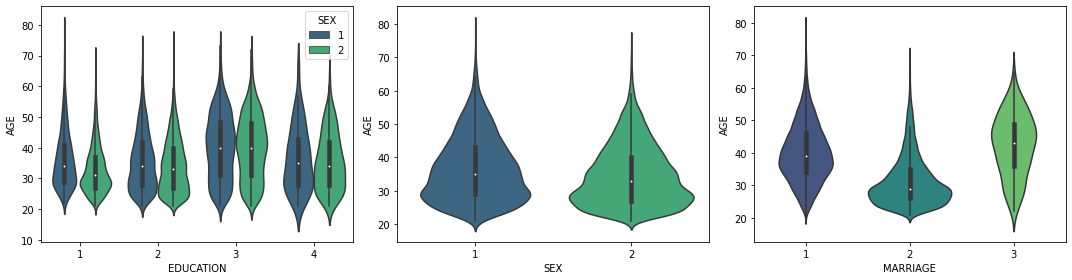

In [14]:
# figure setup
figure, axs = plt.subplots(nrows=1, ncols=3, figsize=(15,4))
# age and education with hue=sex violinplot
sns.violinplot(data=data, y='AGE', x='EDUCATION', hue='SEX', ax=axs[0], palette='viridis')
# age and sex violinplot
sns.violinplot(data=data, y='AGE', x='SEX', ax=axs[1], palette='viridis')
# age and marriage violinplot
sns.violinplot(data=data, y='AGE', x='MARRIAGE', ax=axs[2], palette='viridis')

plt.tight_layout()

### BILL_AMT# and PAY_AMT#

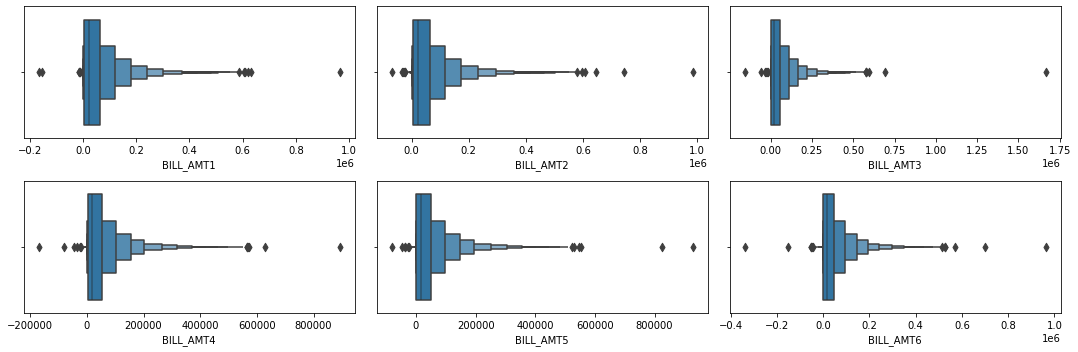

In [15]:
# figure setup
figure, axs = plt.subplots(nrows=2, ncols=3, figsize=(15,5))

# bill_amt# boxenplots
b_layout = [(0,0,'BILL_AMT1'), (0,1,'BILL_AMT2'), (0,2,'BILL_AMT3'), (1,0,'BILL_AMT4'), (1,1,'BILL_AMT5'), (1,2,'BILL_AMT6')]

for x,y,item in b_layout:
    BILL = sns.boxenplot(data=data, x=item, ax=axs[x,y])
    
plt.tight_layout()

There appear to be some extreme outliers present for all BILL_AMTs

The negative values may perhaps indicate overpayment of the bill

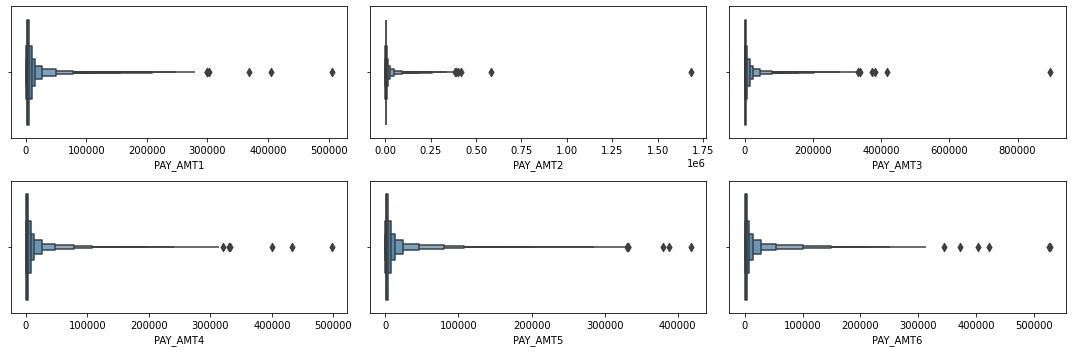

In [16]:
# figure setup
figure, axs = plt.subplots(nrows=2, ncols=3, figsize=(15,5))
# pay_amt# boxenplots
p_layout = [(0,0,'PAY_AMT1'), (0,1,'PAY_AMT2'), (0,2,'PAY_AMT3'), (1,0,'PAY_AMT4'), (1,1,'PAY_AMT5'), (1,2,'PAY_AMT6')]

for x,y,item in p_layout:
    BILL = sns.boxenplot(data=data, x=item, ax=axs[x,y])
    
plt.tight_layout()

There appear to be some extreme outliers present for all PAY_AMTs

Summary of BILL_AMT# and PAY_AMT# via a heatmap and boxenplots:

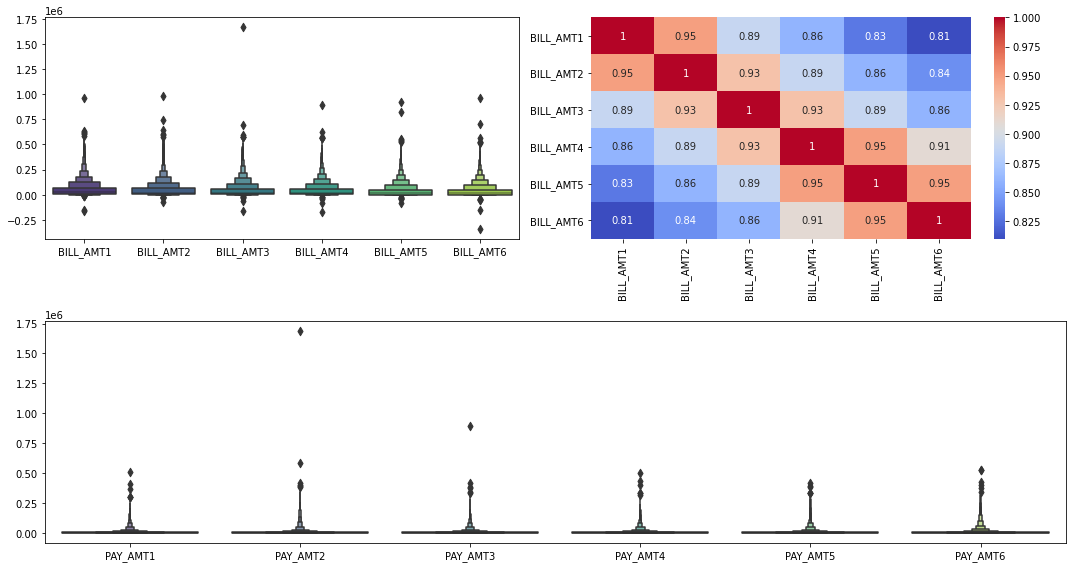

In [17]:
# figure setup
plt.figure(figsize=(15,8))
ax1 = plt.subplot2grid(shape=(2, 2), loc=(0, 0), colspan=1)
ax2 = plt.subplot2grid(shape=(2, 2), loc=(0, 1), colspan=1)
ax3 = plt.subplot2grid(shape=(2, 2), loc=(1, 0), colspan=2)

bill_amt = ['BILL_AMT1','BILL_AMT2','BILL_AMT3','BILL_AMT4','BILL_AMT5', 'BILL_AMT6']

pay_amt = ['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']

sns.boxenplot(data=data[bill_amt], ax=ax1, palette='viridis')
sns.heatmap(data=data[bill_amt].corr().round(2), annot=True, cmap='coolwarm', ax=ax2)

sns.boxenplot(data=data[pay_amt], ax=ax3, showfliers=True, palette='viridis')

plt.tight_layout()

- The BILL_AMTs are highly correlated with each other
- Extreme outliers are present for both BILL_AMTs and PAY_AMTs

## Default Analysis

### SEX

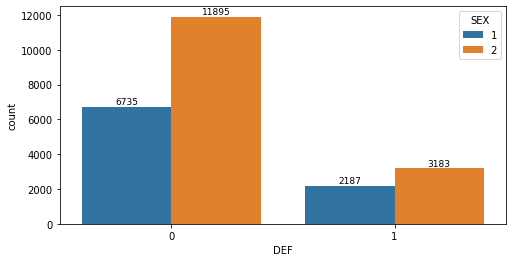

In [18]:
# figure setup
plt.figure(figsize=(8,4))
# plot
cp = sns.countplot(data=data, x='DEF', hue='SEX')
# count labels
for rect in cp.patches:
    cp.text (rect.get_x() + rect.get_width()  / 2,rect.get_height()+ 150,
              rect.get_height(),horizontalalignment='center', fontsize = 9)

Probability of defaulting overall and based on sex:

In [19]:
# table setup
pdf = pd.DataFrame({'Overall': [round((100*(2187+3183)/(24000)),2)], 
              'Male': [round((100*(2187)/(6735+2187)),2)],
              'Female': [round((100*(3183)/(3183+11895)),2)]})
# row title and caption
pdf.rename({0:'Probability of Defaulting (%)'}, inplace=True)
pdf.style.set_caption("Probability (%) of defaulting for males, females and overall")

,Overall,Male,Female
Probability of Defaulting (%),22.380000,24.510000,21.110000


### EDUCATION and SEX

In [20]:
# function to annotate bars for facetgrid obtained from: 
def bar_annot(axs=None, **kwargs):
    axs = plt.gca()
    for j in axs.patches:
         axs.annotate('{{:{:s}}}'.format('d').format(j.get_height()), (j.get_x() + (0.5*j.get_width()), j.get_height()),
                     xytext=(0, 5), va='center', textcoords='offset points', ha='center', **kwargs)

c:\python38\lib\site-packages\seaborn\axisgrid.py:643: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


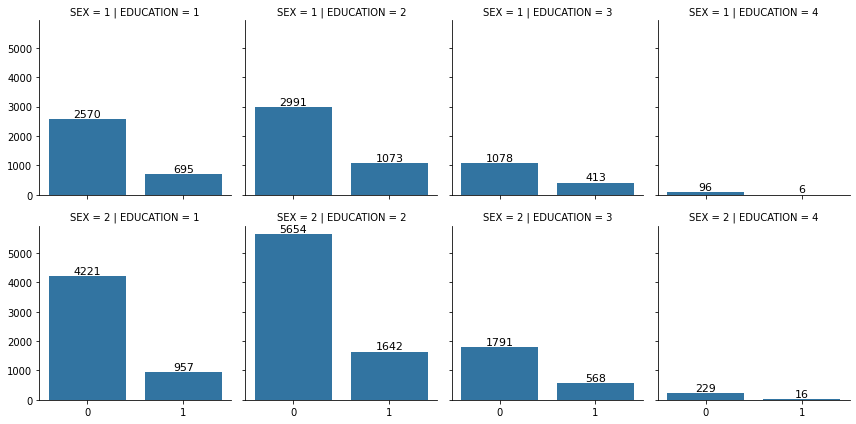

In [21]:
# facet grid plot for education and sex
fg = sns.FacetGrid(data, col='EDUCATION', row='SEX', palette='viridis')
fg.map(sns.countplot, 'DEF')
# count label
fg.map(bar_annot, fontsize=11, color='k')

Probability of defaulting for overall, males and females based on education:

In [22]:
# overall
g = [round((100*(695+957)/(695+957+2570+4221)),2), round((100*(1073+1642)/(1073+1642+2991+5654)),2),
     round((100*(568+413)/(568+413+1078+1791)),2), round((100*(6+16)/(6+16+96+229)),2)]
# male
m = [round((100*(695)/(695+2570)),2), round(100*(1073)/(1073+2991),2), 
     round((100*(413)/(413+1078)),2), round((100*(6)/(6+96)),2)]
# female
f = [round((100*(957)/(957+4221)),2), round((100*(1642)/(1642+5654)),2), 
     round((100*(568)/(568+1791)),2), round((100*(16)/(16+229)),2)]

# table
probs = pd.DataFrame(data={1: list(zip(g,m,f))[0], 
                   2: list(zip(g,m,f))[1],
                   3: list(zip(g,m,f))[2],  
                   4: list(zip(g,m,f))[3]})
# row titles and table caption
probs.rename({0:'Overall',1:'Male',2:'Female'}, inplace=True)
probs.style.set_caption('Probability (%) of defaulting for males, females and overall, based on education')

,1,2,3,4
Overall,19.570000,23.900000,25.480000,6.340000
Male,21.290000,26.400000,27.700000,5.880000
Female,18.480000,22.510000,24.080000,6.530000


### MARRIAGE and SEX

c:\python38\lib\site-packages\seaborn\axisgrid.py:643: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


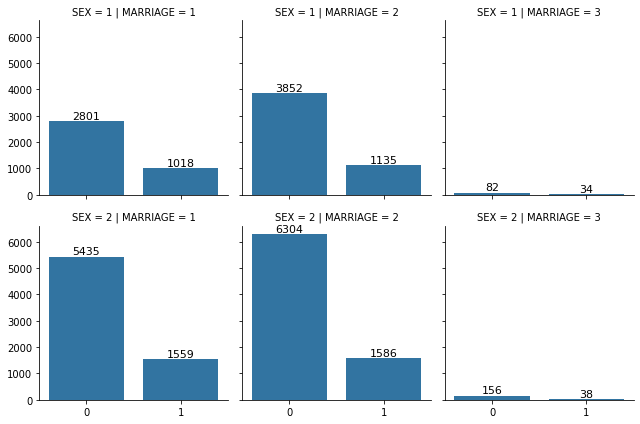

In [23]:
# factgrid plot for marriage and sex
dfs = sns.FacetGrid(data, col='MARRIAGE', row='SEX', palette='viridis')
# plot
dfs.map(sns.countplot, 'DEF')
# count labels
dfs.map(bar_annot, fontsize=11, color='k')

In [24]:
# overall
norm = [round((100*(1018+1559)/(1018+1559+2801+5435)),2), round((100*(1135+1586)/(1135+1586+3852+6304)),2),
     round((100*(38+34)/(38+34+82+156)),2)]
# male
man = [round((100*(1018)/(1018+2801)),2), round((100*(1135)/(1135+3852)),2),
     round((100*(34)/(38+82)),2)]
# female
fem = [round((100*(1559)/(1559+5435)),2), round((100*(1586)/(1586+6304)),2),
     round((100*(38)/(38+156)),2)]
# table
mprobs = pd.DataFrame(data={1: list(zip(norm,man,fem))[0], 
                   2: list(zip(g,m,f))[1],
                   3: list(zip(g,m,f))[2]})
# row title and table caption
mprobs.rename({0:'Overall',1:'Male',2:'Female'}, inplace=True)
mprobs.style.set_caption('Probability (%) of defaulting for males, females and overall, based on marital status')

,1,2,3
Overall,23.830000,23.900000,25.480000
Male,26.660000,26.400000,27.700000
Female,22.290000,22.510000,24.080000


### PAY_#, BILL_AMT and PAY_AMT

In [25]:
# pearson correlations for PAY_# and DEF
data[['PAY_1','PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'DEF']].corr()[['DEF']][:-1].T

,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
DEF,0.391847,0.323103,0.281859,0.262582,0.260037,0.240026


In [26]:
# pearson correlations for BILL_AMT# and DEF
data[['BILL_AMT1', 'BILL_AMT2','BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'DEF']].corr()[['DEF']][:-1].T

,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6
DEF,-0.022493,-0.016201,-0.01507,-0.009682,-0.006495,-0.005609


In [27]:
# pearson correlations for PAY_AMT# and DEF
data[['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6','DEF']].corr()[['DEF']][:-1].T

,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
DEF,-0.077859,-0.06161,-0.058935,-0.058059,-0.052869,-0.056756


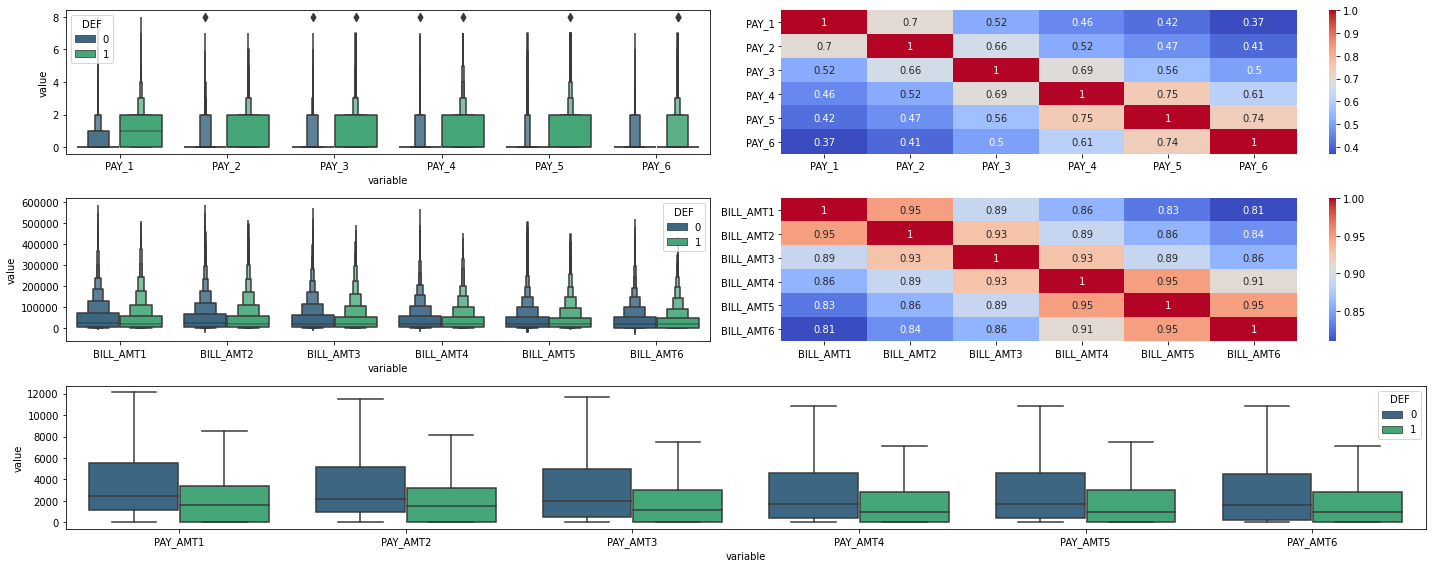

In [28]:
# figure setup
plt.figure(figsize=(20,8))
ax1 = plt.subplot2grid(shape=(3, 2), loc=(0, 0), colspan=1)
ax2 = plt.subplot2grid(shape=(3, 2), loc=(0, 1), colspan=1)
ax3 = plt.subplot2grid(shape=(3, 2), loc=(1, 0), colspan=1)
ax4 = plt.subplot2grid(shape=(3, 2), loc=(1, 1), colspan=1)
ax5 = plt.subplot2grid(shape=(3, 2), loc=(2, 0), colspan=2)
#PAY_# boxenplot 
pdata = data[['PAY_1','PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'DEF']]
pdata = pdata.melt(id_vars='DEF')
sns.boxenplot(data=pdata, x='variable', y='value', hue='DEF', showfliers=True, palette='viridis', ax=ax1)
# BILL_AMT# boxenplot
bdata = data[['BILL_AMT1', 'BILL_AMT2','BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'DEF']]
bdata = bdata.melt(id_vars='DEF')
sns.boxenplot(data=bdata, x='variable', y='value', hue='DEF', ax=ax3,showfliers=False, palette='viridis')
# PAY_AMT# boxplot
pydata = data[['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6','DEF']]
pydata = pydata.melt(id_vars='DEF')
sns.boxplot(data=pydata, x='variable', y='value', hue='DEF', ax=ax5, showfliers=False, palette='viridis')
#PAY_# heatmap
sns.heatmap(data=data[['PAY_1','PAY_2','PAY_3','PAY_4','PAY_5', 'PAY_6']].corr().round(2), annot=True, cmap='coolwarm', ax=ax2)
#BILL_AMT# heatmap
sns.heatmap(data=data[bill_amt].corr().round(2), annot=True, cmap='coolwarm', ax=ax4)

plt.tight_layout()

### LIMIT_BAL and AGE

<AxesSubplot:xlabel='LIMIT_BAL', ylabel='Count'>

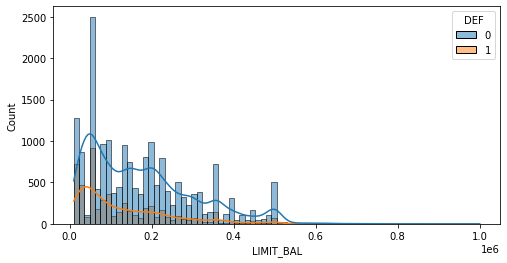

In [29]:
#limit_bal histogram with hue=DEF
plt.figure(figsize=(8,4))

sns.histplot(data=data, x='LIMIT_BAL', hue='DEF', kde=True, alpha=0.5)

- General trend of increasing LIMIT_BAL decreasing default and non default
- A few of the LIMIT_BAL are very common when compared to the rest

In [30]:
# pearson correlation for LIMIT_BAL and DEF
data[['DEF','LIMIT_BAL']].corr()[['DEF']][1:]

,DEF
LIMIT_BAL,-0.148726


<AxesSubplot:xlabel='AGE', ylabel='Count'>

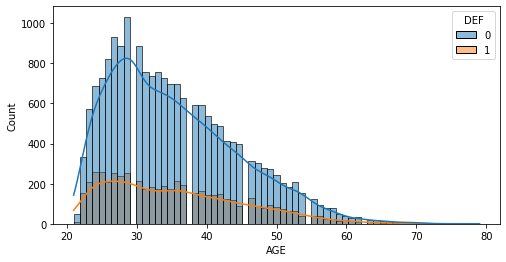

In [31]:
#age histogram with hue=DEF
plt.figure(figsize=(8,4))
sns.histplot(data=data, x='AGE', hue='DEF', kde=True)

Investigating the probabilty of defaulting based on age

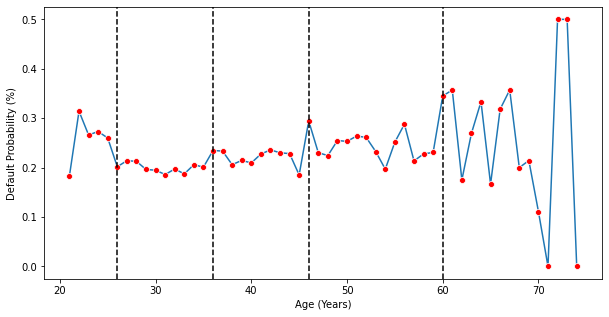

In [32]:
prob = data.groupby(by=['AGE','DEF']).count()[['ID']]

di=[]
# probability of defaulting for each of the ages
for i in range(data['AGE'].max()):
    if i in {i for i in data['AGE']}:
        p = (data[(data['AGE']==i) & (data['DEF']==1)].count()[0])/(data[(data['AGE']==i) & (data['DEF']==0)].count()[0]+data[(data['AGE']==i) & (data['DEF']==1)].count()[0])
        di.append(p)
# plot
plt.figure(figsize=(10,5))
sns.lineplot(x=[i for i in range(21,21+len(di))], y=di, marker='o', markerfacecolor='r')
plt.xlabel('Age (Years)')
plt.ylabel('Default Probability (%)')
# vertical line plots to group similar probabilities
plt.axvline(26, linestyle='--', color='k')
plt.axvline(36, linestyle='--', color='k')
plt.axvline(46, linestyle='--', color='k')
plt.axvline(60, linestyle='--', color='k')

There is a possibilty of binning the data for age, as there appears to be a trend in age and defaulting

In [33]:
print(f'   < 26: {round(np.mean(di[:5]), 2)}')
print(f'26 - 35: {round(np.mean(di[6:15]), 2)}')
print(f'36 - 45: {round(np.mean(di[16:25]), 2)}')
print(f'46 - 59: {round(np.mean(di[26:39]), 2)}')
print(f'   > 59: {round(np.mean(di[40:]), 2)}')

   < 26: 0.26
26 - 35: 0.2
36 - 45: 0.22
46 - 59: 0.24
   > 59: 0.25


Summary plot of AGE and LIMIT_BAL regarding defaulting:

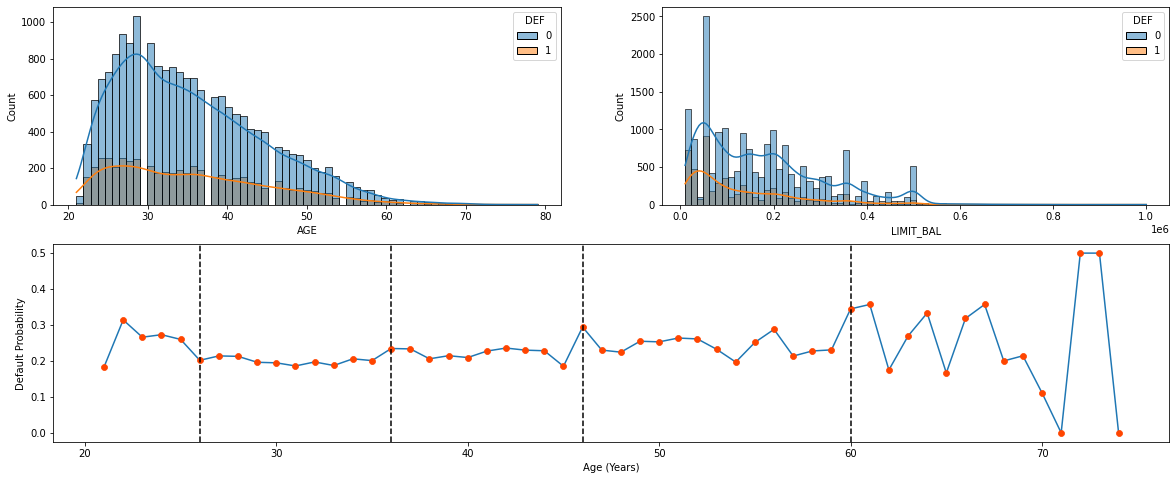

In [34]:
# figure setup
plt.figure(figsize=(20,8))
ax1 = plt.subplot2grid(shape=(2, 2), loc=(0, 0), colspan=1)
ax2 = plt.subplot2grid(shape=(2, 2), loc=(0, 1), colspan=1)
ax3 = plt.subplot2grid(shape=(2, 2), loc=(1, 0), colspan=2)
# age and histplot with DEF
sns.histplot(data=data, x='AGE', hue='DEF', kde=True, ax=ax1)
# limit_bal and histplot with DEF
sns.histplot(data=data, x='LIMIT_BAL', hue='DEF', kde=True, alpha=0.5, ax=ax2)
# age and probabilty of defaulting plot
sns.lineplot(x=[i for i in range(21,21+len(di))], y=di, marker='o', 
             markerfacecolor='orangered',markeredgecolor='orangered', ax=ax3)

plt.xlabel('Age (Years)')
plt.ylabel('Default Probability')
plt.axvline(26, linestyle='--', color='k')
plt.axvline(36, linestyle='--', color='k')
plt.axvline(46, linestyle='--', color='k')
plt.axvline(60, linestyle='--', color='k')

## Checking for Multicolinearity

In [35]:
# Setting up vif dataframe
vif = pd.DataFrame()

df_v= data.drop(['ID','DEF'],axis=1)

vif['Features']= df_v.columns
vif['VIF'] = [variance_inflation_factor(df_v.values,item) for item in range(df_v.shape[1])]

vif

,Features,VIF
0,LIMIT_BAL,3.646321
1,SEX,9.446878
2,EDUCATION,7.488227
3,MARRIAGE,6.452924
4,AGE,11.169470
5,PAY_1,2.491748
6,PAY_2,3.070920
7,PAY_3,2.948956
8,PAY_4,3.404941
9,PAY_5,3.592425


- VIFs greater than 5 exhbit multicollinearity
- BILL_AMTs have very high VIFs
- AGE, MARRIAGE, EDUCATION, SEX also have high VIFs

# Data Transformations

## Outliers

IQR will be utilised to identify and potentially remove outliers identified in the exploratory analysis. IQR will be utilised as it can used when the data is skewed, as is the case for this dataset

In [36]:
ndata = data

#### IQR and Plot Function

In [37]:
def outliers(column):
    # Lower quartile
    Q1 = data[column].quantile(0.25)
    # Upper quartile
    Q3 = data[column].quantile(0.75)
    # IQR
    IQR = Q3 - Q1
    # Maximum value
    Max_V = Q3 + 1.5*IQR
    # Minimum value 
    Min_V = Q1 - 1.5*IQR
    # Displaying the maximum and minimum value obtained
    print(f'{column}: Minimum value: {Min_V}        Maximum value: {Max_V}')
    
    # Plots
    figure, axs = plt.subplots(1,3, figsize=(20,5))
    # Box plot
    sns.boxplot(data=data, x=column, ax=axs[0])
    # Histogram plot
    sns.histplot(data=data, x=column, ax=axs[1])
    # Maximum value line
    axs[1].axvline(x=Max_V, color='r', linestyle='--')
    # Minimum value line
    axs[1].axvline(x=Min_V, color='r', linestyle='--')
    # scatter plot
    sns.scatterplot(data=data, x='ID',y=column, ax=axs[2])
    # Maximum value line
    axs[2].axhline(y=Max_V, color='r', linestyle='--')
    # Minimum value line
    axs[2].axhline(y=Min_V, color='r', linestyle='--')

#### AGE Outliers Plot

AGE: Minimum value: 8.5        Maximum value: 60.5


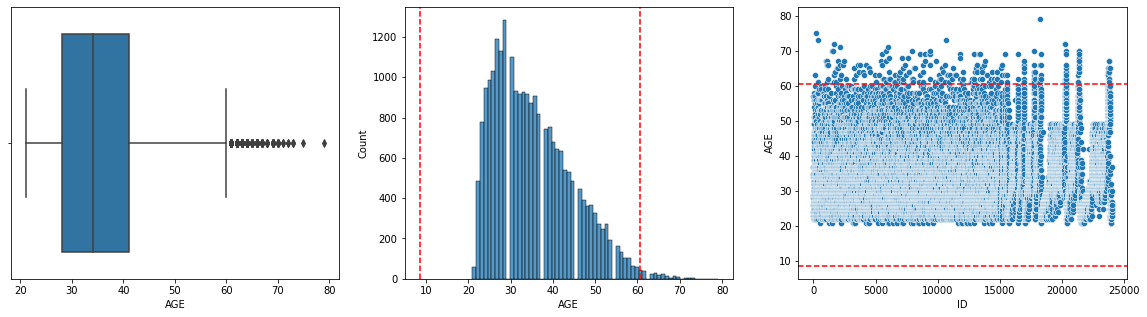

In [38]:
# Age Outliers
outliers('AGE')

#### LIMIT_BAL Outliers Plot

LIMIT_BAL: Minimum value: -235000.0        Maximum value: 525000.0


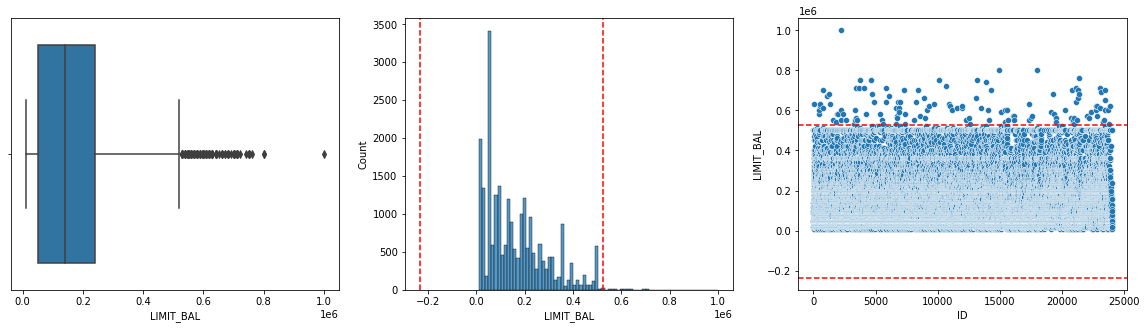

In [39]:
# Age Outliers
outliers('LIMIT_BAL')

#### BILL_AMT Outliers Plot

BILL_AMT1: Minimum value: -89590.5        Maximum value: 159001.5
BILL_AMT2: Minimum value: -86395.625        Maximum value: 152255.375
BILL_AMT3: Minimum value: -82013.25        Maximum value: 144084.75
BILL_AMT4: Minimum value: -72432.75        Maximum value: 126961.25
BILL_AMT5: Minimum value: -70269.75        Maximum value: 121756.25
BILL_AMT6: Minimum value: -70107.5        Maximum value: 120138.5


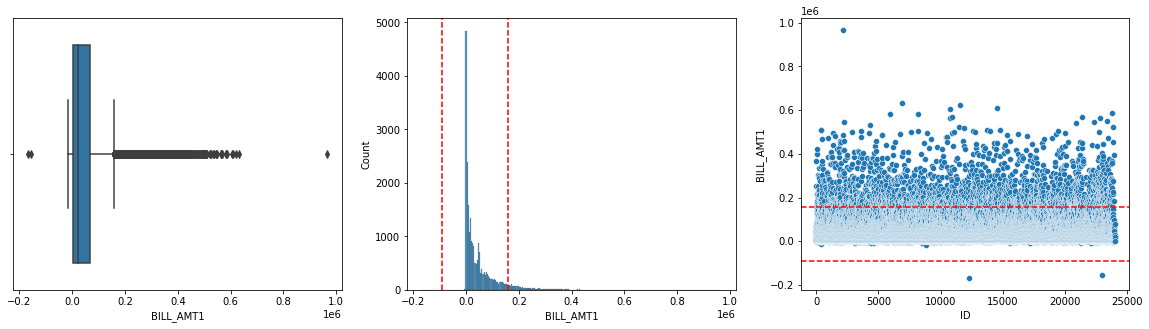

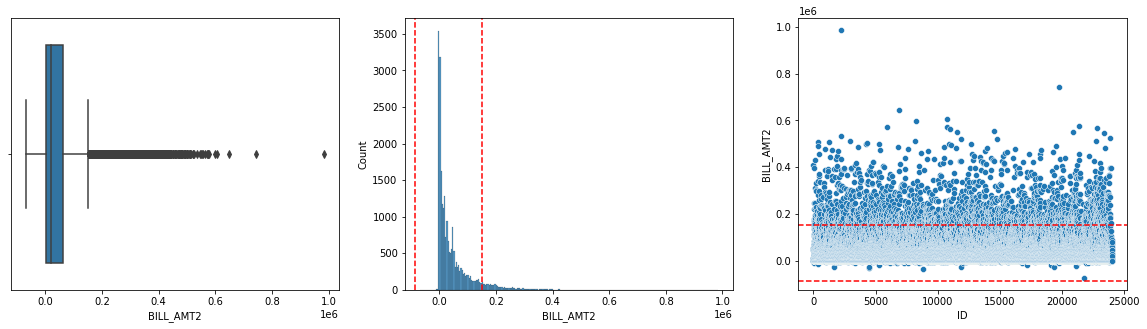

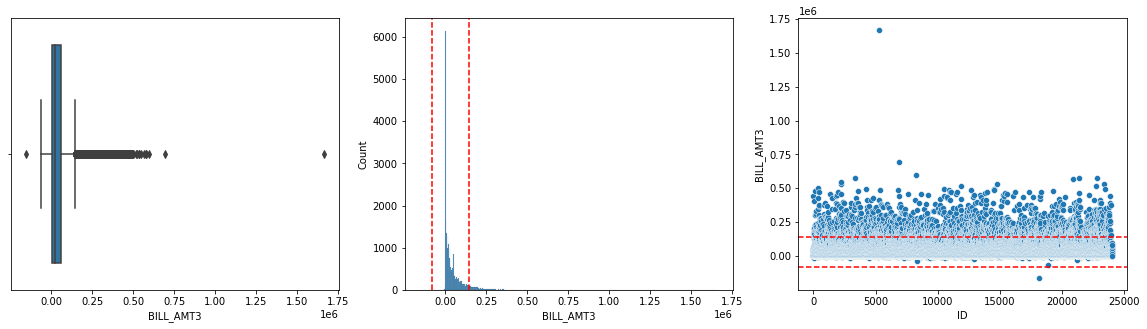

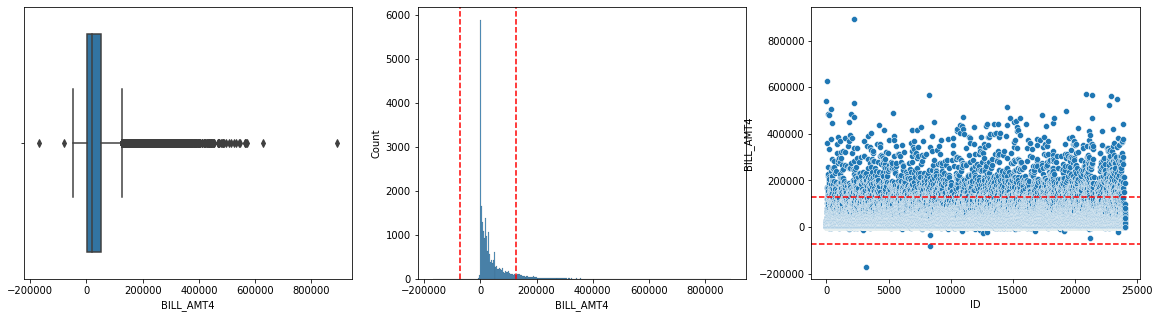

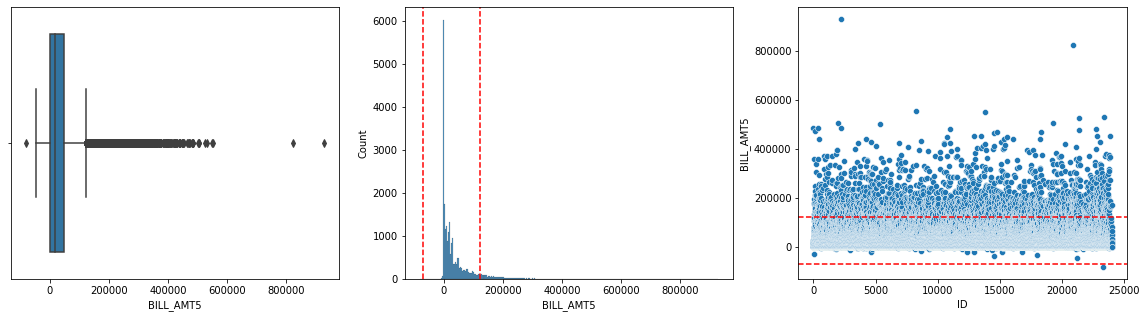

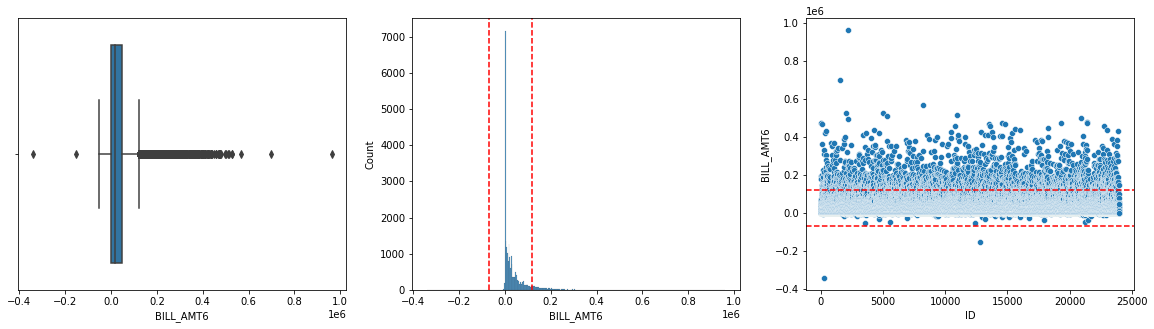

In [40]:
BILL_AMT = ['BILL_AMT1', 'BILL_AMT2','BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5','BILL_AMT6']

for i in BILL_AMT:
    outliers(i)

#### PAY_AMT Outliers Plot

PAY_AMT1: Minimum value: -5000.0        Maximum value: 11000.0
PAY_AMT2: Minimum value: -5500.0        Maximum value: 11300.0
PAY_AMT3: Minimum value: -5573.375        Maximum value: 10299.625
PAY_AMT4: Minimum value: -5300.625        Maximum value: 9580.375
PAY_AMT5: Minimum value: -5397.5        Maximum value: 9646.5
PAY_AMT6: Minimum value: -5848.125        Maximum value: 9908.875


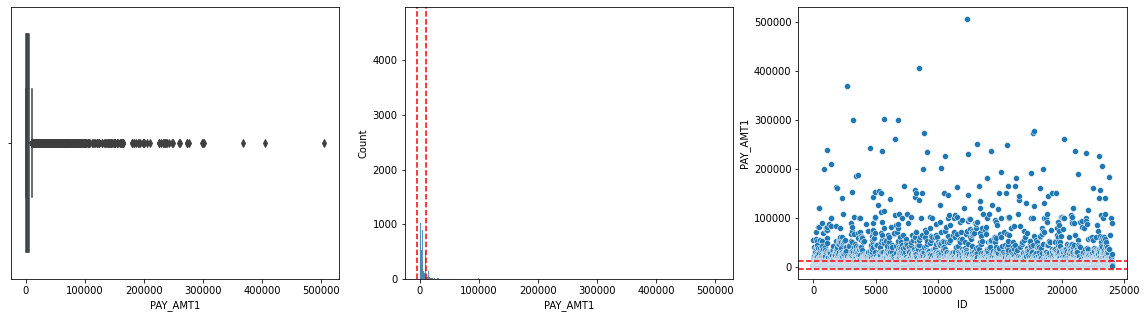

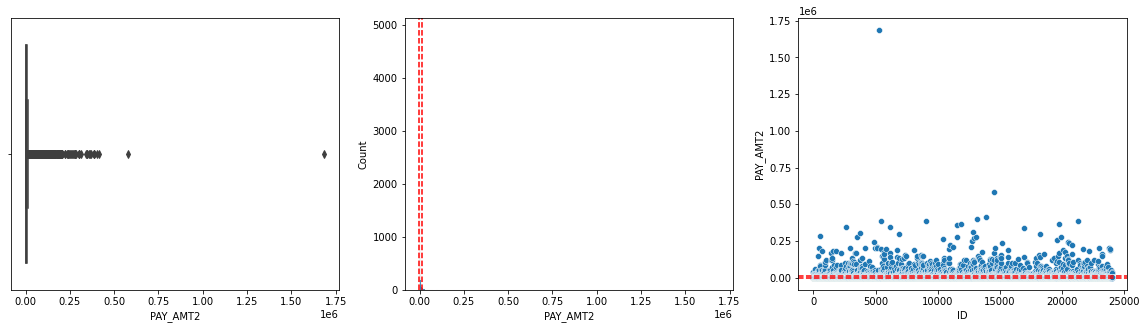

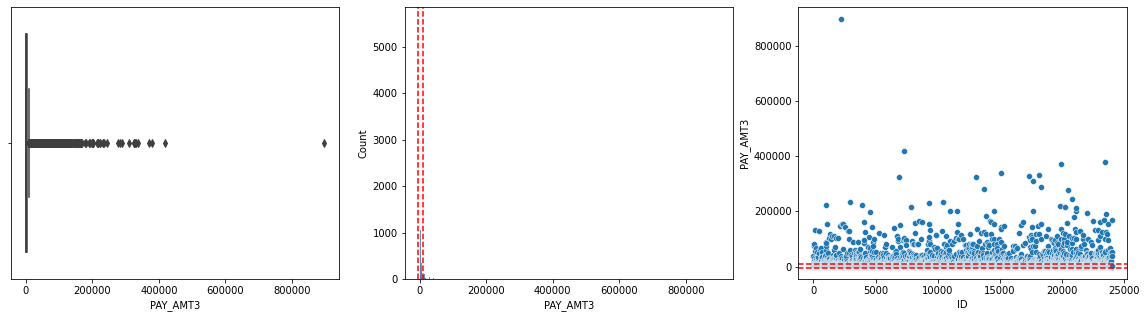

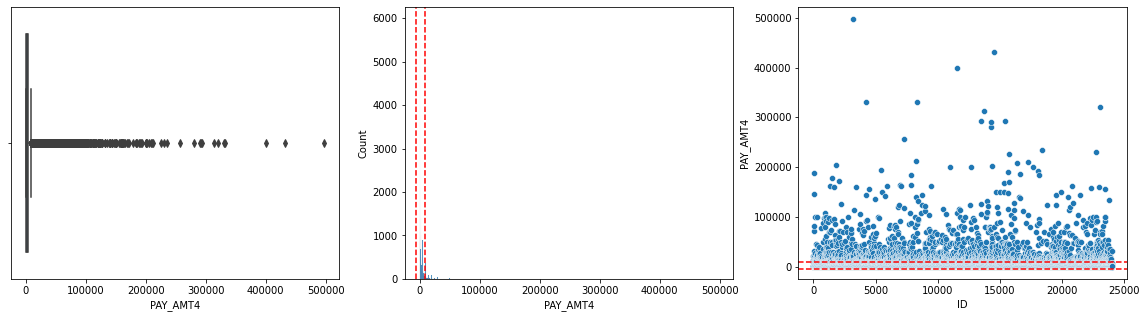

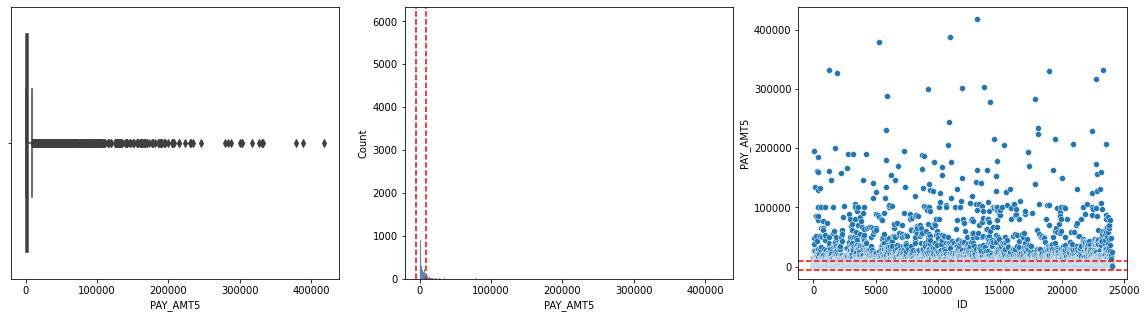

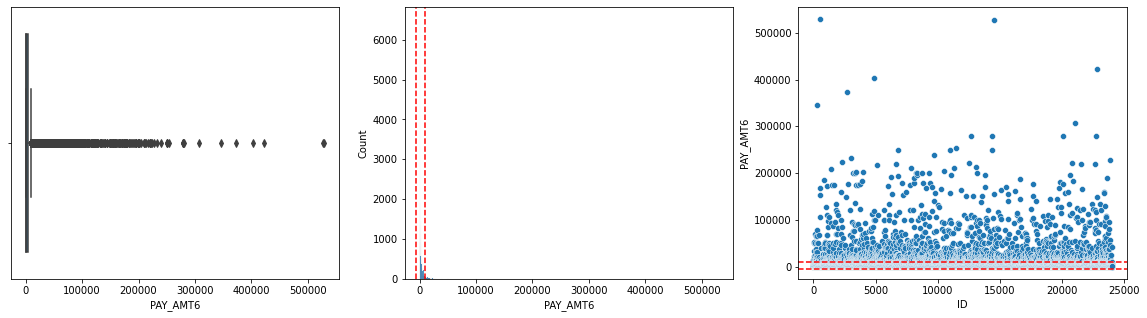

In [41]:
PAY_AMT = ['PAY_AMT1','PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']

for i in PAY_AMT:
    outliers(i)

It would be hard to justify such a large amount of data being anomalous, given that outliers are meant to be rare in nature.  Furthermore, it is possible that many of the outliers are a result of natural variation, data entry error and data processing errors.  As such, the IQR method will be discarded, and all only extreme outliers identified during the exploratoty analysis will be removed

Also a combination of local outlier factor and random forest will be used to detect and remove outliers which will be carried out in the model training and validation section in order to avoid data leakage

### Removing Extreme Outliers

In [42]:
ndata = data

LIM_BAL outliers:

In [43]:
ndata.drop(ndata[ndata['LIMIT_BAL']>900000].index, axis=0, inplace=True)

BILL_AMT# outliers

In [44]:
for i in ['BILL_AMT1', 'BILL_AMT2','BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']:
    ndata.drop(ndata[ndata[i]>700000].index, axis=0, inplace=True)
    ndata.drop(ndata[ndata[i]<-100000].index, axis=0, inplace=True)

PAY_AMT# outliers

In [45]:
for i in ['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']:
    ndata.drop(ndata[ndata[i]>400000].index, axis=0, inplace=True)

### Data Loss and EPV

In [46]:
print(f'Data Loss: {round((100*(24000 - ndata.shape[0]) / 24000),2)}%')

Data Loss: 0.09%


Checking EPV after removing extreme outliers

In [47]:
minimum = min(data[data['DEF']==1].shape[0], ndata[ndata['DEF']==1].shape[0])

minimum/23

233.3913043478261

## Feature Engineering

### Total Bill Ratio

- The BILL_AMT columns can be summed together to reduce multicollinearity, while having the benefit of providing further information relating to how close the individual is to reaching their limit balance

In [48]:
ndata['TOT_BILL_RAT'] = ((ndata['BILL_AMT6'] + ndata['BILL_AMT5'] + ndata['BILL_AMT4'] + ndata['BILL_AMT3'] + ndata['BILL_AMT2'] + ndata['BILL_AMT1']) / 6) /ndata['LIMIT_BAL']

In [49]:
vif = pd.DataFrame()
df_v= ndata.drop(['ID','DEF','BILL_AMT1', 'BILL_AMT2','BILL_AMT3', 'BILL_AMT4',
                  'BILL_AMT5', 'BILL_AMT6', 'LIMIT_BAL'],axis=1)

vif['Features']= df_v.columns
vif['VIF'] = [variance_inflation_factor(df_v.values,item) for item in range(df_v.shape[1])]

vif

,Features,VIF
0,SEX,9.171821
1,EDUCATION,7.407741
2,MARRIAGE,6.570184
3,AGE,9.701341
4,PAY_1,2.490495
5,PAY_2,3.081578
6,PAY_3,2.947594
7,PAY_4,3.406868
8,PAY_5,3.593206
9,PAY_6,2.506981


Multicollinearity has been reduced and new column with more information has been produced

### Average Expense

- As found in the exploratory analysis, the PAY_AMT columns have very little correlation to DEF.
- Thus, in an attempt to derive a greater relationship between PAY_AMT columns and DEF, they can be combined with LIMIT_BAL and BILL_AMT# columns to provide an average expense for the individual
- This should in turn provide a greater insight into whether an individual will deafult

In [50]:
ndata['AV_EXP5'] = (ndata['BILL_AMT5'] - ndata['BILL_AMT6'] - ndata['PAY_AMT5']) / ndata['LIMIT_BAL']

ndata['AV_EXP4'] = ((ndata['AV_EXP5'] + ndata['BILL_AMT4'] - ndata['BILL_AMT5'] - ndata['PAY_AMT4']) / 2) / ndata['LIMIT_BAL']

ndata['AV_EXP3'] = ((ndata['AV_EXP4'] + ndata['BILL_AMT3'] - ndata['BILL_AMT4'] - ndata['PAY_AMT3']) / 3) / ndata['LIMIT_BAL']

ndata['AV_EXP2'] = ((ndata['AV_EXP3'] + ndata['BILL_AMT2'] - ndata['BILL_AMT3'] - ndata['PAY_AMT2']) / 4) / ndata['LIMIT_BAL']

ndata['AV_EXP1'] = (ndata['AV_EXP2'] + ndata['BILL_AMT1'] - ndata['BILL_AMT2'] - ndata['PAY_AMT1'] / 5) / ndata['LIMIT_BAL']

In [51]:
vif = pd.DataFrame()
df_v= ndata.drop(['ID','DEF','BILL_AMT1', 'BILL_AMT2','BILL_AMT3', 'BILL_AMT4', 
                'BILL_AMT5', 'BILL_AMT6', 'LIMIT_BAL','PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6'],axis=1)
vif['Features']= df_v.columns
vif['VIF'] = [variance_inflation_factor(df_v.values,item) for item in range(df_v.shape[1])]
vif

,Features,VIF
0,SEX,9.166200
1,EDUCATION,7.375351
2,MARRIAGE,6.564428
3,AGE,9.438131
4,PAY_1,2.488269
5,PAY_2,3.091631
6,PAY_3,2.981679
7,PAY_4,3.429825
8,PAY_5,3.617153
9,PAY_6,2.529840


### Binning the AGE Column

- In the exploratory analysis it was found the certain age groups have a greater probability of deafulting.
- Hence the AGE column can be binned and label coding can be applied, with the highest value being assigned to the age group most likely to default and the lowest value to the age group least likely to default.
- This should also aid in reducing multicollinearity, as the VIF for age is rather high

In [52]:
# binning age based on the catergoreis derived in the exploratory analysis

bins = [20, 25, 35, 45, 59, 100]
bins_names = [5, 1, 2, 3, 4]

ndata['AGE_BIN'] = pd.cut(ndata['AGE'], bins, labels=bins_names)

In [53]:
vif = pd.DataFrame()
df_v = ndata.drop(['ID','DEF','BILL_AMT1', 'BILL_AMT2','BILL_AMT3', 'BILL_AMT4', 
                'BILL_AMT5', 'BILL_AMT6', 'LIMIT_BAL','PAY_AMT1',
                'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6','AGE'],axis=1)

vif['Features'] = df_v.columns
vif['VIF'] = [variance_inflation_factor(df_v.values,item) for item in range(df_v.shape[1])]

vif

,Features,VIF
0,SEX,7.803194
1,EDUCATION,6.079543
2,MARRIAGE,6.621140
3,PAY_1,2.486049
4,PAY_2,3.090912
5,PAY_3,2.983052
6,PAY_4,3.429974
7,PAY_5,3.617143
8,PAY_6,2.529980
9,TOT_BILL_RAT,2.378975


### Combining the SEX and MARRIAGE Columns

- As found in the exploratory analysis a relationship was observed between the marital status and sex with regards to probability of defaulting.
- Thus, these catergoris can be combined via label encoding with the highest value being assigned to the marital status and sex most likely to default and the lowest value to the marital status and sex least likely to default.
- This should also aid in reducing multicollinearity, as the SEX and MARRIAGE columns have high VIFs

In [54]:
ndata['SEX_MAR'] = 0
# married man
ndata.loc[((ndata['SEX'] == 1) & (ndata['MARRIAGE'] == 1)) , 'SEX_MAR'] = 4
# single man
ndata.loc[((ndata['SEX'] == 1) & (ndata['MARRIAGE'] == 2)) , 'SEX_MAR'] = 5
# other man
ndata.loc[((ndata['SEX'] == 1) & (ndata['MARRIAGE'] == 3)) , 'SEX_MAR'] = 6 
# married woman
ndata.loc[((ndata['SEX'] == 2) & (ndata['MARRIAGE'] == 1)) , 'SEX_MAR'] = 2
# single woman
ndata.loc[((ndata['SEX'] == 2) & (ndata['MARRIAGE'] == 2)) , 'SEX_MAR'] = 1
# other woman
ndata.loc[((ndata['SEX'] == 2) & (ndata['MARRIAGE'] == 3)) , 'SEX_MAR'] = 3 

In [55]:
vif = pd.DataFrame()
df_v = ndata.drop(['ID','DEF','BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5',
                   'BILL_AMT6', 'LIMIT_BAL','PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4',
                   'PAY_AMT5', 'PAY_AMT6','AGE','SEX','MARRIAGE'], axis=1)

vif['Features'] = df_v.columns
vif['VIF'] = [variance_inflation_factor(df_v.values,item) for item in range(df_v.shape[1])]

vif

,Features,VIF
0,EDUCATION,4.510458
1,PAY_1,2.483321
2,PAY_2,3.087338
3,PAY_3,2.982448
4,PAY_4,3.429472
5,PAY_5,3.616383
6,PAY_6,2.529349
7,TOT_BILL_RAT,2.359230
8,AV_EXP5,1.025224
9,AV_EXP4,1.046257


### Combining the SEX and EDUCATION Columns

- As found in the exploratory analysis a relationship was observed between education and sex with regards to probability of defaulting.
- These catergoris can be combined via label encoding with the highest value being assigned to the education and sex most likely to default and the lowest value to the education and sex least likely to default.
- This should also aid in reducing multicollinearity.

In [56]:
ndata['SEX_ED'] = 0

ndata.loc[((ndata['SEX'] == 1) & (ndata['EDUCATION'] == 1)) , 'SEX_ED'] = 2
ndata.loc[((ndata['SEX'] == 1) & (ndata['EDUCATION'] == 2)) , 'SEX_ED'] = 4
ndata.loc[((ndata['SEX'] == 1) & (ndata['EDUCATION'] == 3)) , 'SEX_ED'] = 6
ndata.loc[((ndata['SEX'] == 1) & (ndata['EDUCATION'] == 4)) , 'SEX_ED'] = 8

ndata.loc[((ndata['SEX'] == 2) & (ndata['EDUCATION'] == 1)) , 'SEX_ED'] = 1
ndata.loc[((ndata['SEX'] == 2) & (ndata['EDUCATION'] == 2)) , 'SEX_ED'] = 3
ndata.loc[((ndata['SEX'] == 2) & (ndata['EDUCATION'] == 3)) , 'SEX_ED'] = 5
ndata.loc[((ndata['SEX'] == 2) & (ndata['EDUCATION'] == 4)) , 'SEX_ED'] = 7

In [57]:
vif = pd.DataFrame()
df_v = ndata.drop(['ID','DEF','BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5',
                   'BILL_AMT6', 'LIMIT_BAL','PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4',
                   'PAY_AMT5', 'PAY_AMT6','AGE','SEX','MARRIAGE', 'EDUCATION'], axis=1)

vif['Features'] = df_v.columns
vif['VIF'] = [variance_inflation_factor(df_v.values,item) for item in range(df_v.shape[1])]

vif

,Features,VIF
0,PAY_1,2.480007
1,PAY_2,3.086823
2,PAY_3,2.982370
3,PAY_4,3.429512
4,PAY_5,3.616117
5,PAY_6,2.529424
6,TOT_BILL_RAT,2.313714
7,AV_EXP5,1.024414
8,AV_EXP4,1.046157
9,AV_EXP3,1.047115


Dataframe that will be utilised to build the model:

In [58]:
model_data = ndata.drop(['ID','BILL_AMT1', 'BILL_AMT2','BILL_AMT3', 'BILL_AMT4','BILL_AMT5',
                        'BILL_AMT6', 'LIMIT_BAL','PAY_AMT1','PAY_AMT2','PAY_AMT3', 'PAY_AMT4',
                        'PAY_AMT5', 'PAY_AMT6','AGE','SEX','MARRIAGE', 'EDUCATION'],axis=1)

# Model and Validation

## Removing Final Outliers

- Local outlier factor and isolation forest will be utlised to remover outliers, but first the data will have need to be split into a training and validation set to avoid data leakage

In [59]:
# input variables
X = model_data.drop(['DEF'], axis=1)
# output variables
y = model_data['DEF']

In [60]:
# train and validation split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=101)
# applying standard scaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_val = sc.transform(X_val)

Function to apply local outlier factor and isolation forest, as well as remove the common outliers

In [61]:
def outlier_removal(X_train, X_val, y_train, y_val):
    
    # isolation forest 
    isolation_forest = IsolationForest(random_state=11)
    iso_for_outliers = isolation_forest.fit_predict(X_train)
    # local outlier factor
    local_outf = LocalOutlierFactor(n_neighbors=5)
    local_outf_outliers = local_outf.fit_predict(X_train)
    # identifying the outliers
    n_iso_for_outliers = len(np.where(iso_for_outliers == -1)[0])
    n_local_outf_outliers = len(np.where(local_outf_outliers == -1)[0])
    # identifying the common outliers
    common = (iso_for_outliers == -1)&(local_outf_outliers == -1)
    n_common = np.sum(common)
    # Deleting the common outliers
    X_train = pd.DataFrame(X_train)
    X_train_ = X_train.drop(X_train[common].index)
    # converting from pandas dataframe to numpy array
    X_train_ = X_train_.to_numpy()
    # y train for the corresponding x train 
    y_train.reset_index(drop=True, inplace=True)
    y_train = pd.DataFrame(y_train)
    y_train_ = y_train.drop(X_train[common].index)
    # accessing the training data
    outlier_removal.xtrain = X_train_
    outlier_removal.ytrain = y_train_
    # accessing the validation data
    outlier_removal.xval =  X_val
    outlier_removal.yval =  y_val

In [62]:
# function for local outlier factor and isolation forest
outlier_removal(X_train, X_val, y_train, y_val)
# train data with outliers removed
y_train = outlier_removal.ytrain
X_train = outlier_removal.xtrain
# validation data
y_val = outlier_removal.yval
X_val = outlier_removal.xval

## Models

- SMOTE will be used to tackle the class imbalanced nature of the data set, as this would otherwise lead to bias towards the majority class when training the model.
- Cross Validation will be implemented using stratified sampling, to ensure that the proportions of each feature is the same across the training and validation sets. along with using random shuffling 

Function for learning curve plot

In [63]:
# Learning curve plot function
def plot_learning_curve(train_X, train_y, class_model, cv, train_sizes):
    # setting up the figure, title and axis labels
    plt.figure()
    plt.ylabel('Score')
    plt.xlabel('Training Size')
    plt.title('Learning curve')
    # learning curve
    train_size, train_score, val_score = learning_curve(class_model, train_X, train_y, train_sizes=train_sizes, cv=cv, random_state=11, scoring='roc_auc',
                                                        shuffle=True)
    # standard deviation and mean for the validation set 
    std_val_score = np.std(val_score, axis=1)
    mean_val_score = np.mean(val_score, axis=1)
    # standard deviation and mean for the train set 
    std_train_score  = np.std(train_score, axis=1)
    mean_train_score = np.mean(train_score, axis=1)
    # plotting the standard deviation for the validation set 
    plt.fill_between(x=train_size, y1=(mean_val_score - std_val_score), y2=(mean_val_score + std_val_score), color='green', alpha=0.05)
    # plotting the standard deviation for the train set
    plt.fill_between(x=train_size, y1=(mean_train_score - std_train_score), y2=(mean_train_score + std_train_score), color='red', alpha=0.05)
    # plotting the mean validation score
    plt.plot(train_size, mean_val_score, color='green', label='Cross-Validation Score')
    # plotting the mean train score
    plt.plot(train_size, mean_train_score, color='red', label='Training Score')
    # legend                 
    plt.legend(loc='best')
    
    return plt

Confusion matrix heatmap function

In [64]:
def con_mat_heatmap(con_mat, type_of_dataset):
    # pandas dataframe for confusion matrix
    df_con_mat = pd.DataFrame(con_mat, index=[0,1], columns=[0,1])
    # figure setup
    figure = plt.figure()
    # heatmap for the confusion matrix
    heatmap = sns.heatmap(df_con_mat, annot=True, cmap='Blues', fmt='d', cbar=False)
    # axis label adjustments
    heatmap.yaxis.set_ticklabels(heatmap.yaxis.get_ticklabels(), rotation=360, fontsize=11)
    heatmap.xaxis.set_ticklabels(heatmap.xaxis.get_ticklabels(), fontsize=11)
    # axis and title labels
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title(f'Confusion Matrix for the {type_of_dataset} Set')

### Logisitic Regression

In [65]:
# logistic regression pipeline with smote and logisitic model
lr_pipeline = Pipeline(steps = [['smote', SMOTE(random_state=11)], ['lr', LogisticRegression(random_state=11)]])
# stratified k fold
lr_stratified_kfold = StratifiedKFold(n_splits=10,
                                   shuffle=True,
                                   random_state=11)
# hyperparamater grid for key hyperparameters
# note that a number of parameters were inputed, optimal values were then selected afterwards and inputted 
# to avoid the long runtime
lr_param_grid = {'lr__C': [0.1], 'lr__solver': ['saga'], 'lr__max_iter': [1000]}
# grid search cv to obtain optimal hyperparameters
lr_grid_search = GridSearchCV(estimator=lr_pipeline,
                           param_grid=lr_param_grid,
                           cv=lr_stratified_kfold,
                           return_train_score=True)
# fitting to the train data
lr_grid_search.fit(X_train, np.array(y_train))

GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=11, shuffle=True),
             estimator=Pipeline(steps=[['smote', SMOTE(random_state=11)],
                                       ['lr',
                                        LogisticRegression(random_state=11)]]),
             param_grid={'lr__C': [0.1], 'lr__max_iter': [1000],
                         'lr__solver': ['saga']},
             return_train_score=True)

Best Logistic regression model hyperparameters:

In [66]:
print(lr_grid_search.best_estimator_.get_params()['lr'])

LogisticRegression(C=0.1, max_iter=1000, random_state=11, solver='saga')


Logistic regression learning curve:

<module 'matplotlib.pyplot' from 'c:\\python38\\lib\\site-packages\\matplotlib\\pyplot.py'>

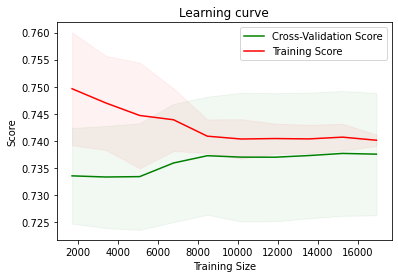

In [67]:
plot_learning_curve(X_train, np.ravel(y_train), lr_grid_search.best_estimator_.get_params()['lr'], 
                     lr_stratified_kfold, np.linspace(0.1, 1.0, 10))

Logistic regression classification report:

In [68]:
print(classification_report(y_val, lr_grid_search.best_estimator_.predict(X_val)))

              precision    recall  f1-score   support

           0       0.87      0.83      0.85      3722
           1       0.49      0.56      0.52      1074

    accuracy                           0.77      4796
   macro avg       0.68      0.70      0.69      4796
weighted avg       0.78      0.77      0.78      4796



Logistic regression confusion matrix:

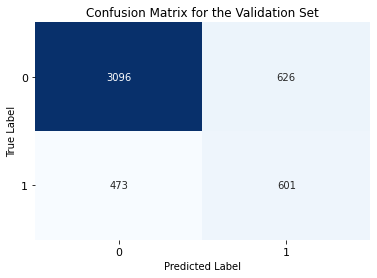

In [69]:
lr_cf = confusion_matrix(y_val, lr_grid_search.best_estimator_.predict(X_val))

con_mat_heatmap(lr_cf, 'Validation')

Logistic regression precision-recall curve plot:

In [70]:
# logisitc regression prediction probabilities
lr_y_pred = lr_grid_search.best_estimator_.predict_proba(X_val)[:,1]
# precision recall curve
lr_prec, lr_rec, _ = precision_recall_curve(y_val, lr_y_pred)

AUC = 0.51


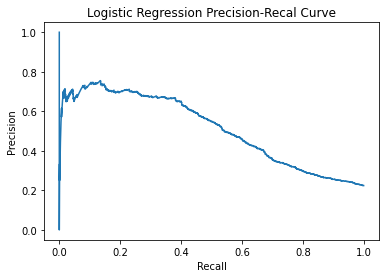

In [71]:
# precision recall curve plot
plt.plot(lr_rec, lr_prec)
# axis labels and title
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Logistic Regression Precision-Recal Curve')
# auc score
print(f'AUC = {round(auc(lr_rec, lr_prec),3)}')

### Random Forest

In [72]:
# random forest pipeline with smote and random forest model
rfc_pipeline = Pipeline(steps = [['smote', SMOTE(random_state=11)],['rfc', RandomForestClassifier(random_state=11)]])
# stratified kfold
rfc_stratified_kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=11)
# hyperparamater grid for key hyperparameters
# note that a number of parameters were inputed, optimal values were then selected afterwards and inputted 
# to avoid the long runtime
rfc_param_grid = {'rfc__max_depth' : [3], 'rfc__max_features': ['sqrt'], 'rfc__criterion': ['entropy'],
                  'rfc__n_estimators': [100]}
# grid search cv to obtain optimal hyperparameters
rfc_grid_search = GridSearchCV(estimator=rfc_pipeline,
                           param_grid=rfc_param_grid,
                           cv=rfc_stratified_kfold,
                           return_train_score=True)
# fitting to the train data
rfc_grid_search.fit(X_train, np.array(y_train))

GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=11, shuffle=True),
             estimator=Pipeline(steps=[['smote', SMOTE(random_state=11)],
                                       ['rfc',
                                        RandomForestClassifier(random_state=11)]]),
             param_grid={'rfc__criterion': ['entropy'], 'rfc__max_depth': [3],
                         'rfc__max_features': ['sqrt'],
                         'rfc__n_estimators': [100]},
             return_train_score=True)

Best random forest hyperparameters:

In [73]:
print(rfc_grid_search.best_estimator_.get_params()['rfc'])

RandomForestClassifier(criterion='entropy', max_depth=3, max_features='sqrt',
                       random_state=11)


Random forest learning curve:

<module 'matplotlib.pyplot' from 'c:\\python38\\lib\\site-packages\\matplotlib\\pyplot.py'>

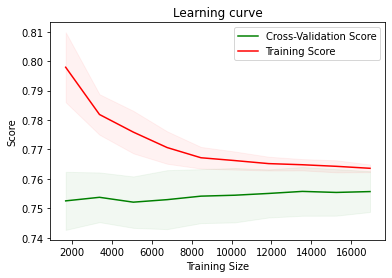

In [74]:
plot_learning_curve(X_train, np.ravel(y_train), rfc_grid_search.best_estimator_.get_params()['rfc'], 
                     rfc_stratified_kfold, np.linspace(0.1, 1.0, 10))

Random forest classification report:

In [75]:
print(classification_report(y_val, rfc_grid_search.best_estimator_.predict(X_val)))

              precision    recall  f1-score   support

           0       0.86      0.86      0.86      3722
           1       0.52      0.54      0.53      1074

    accuracy                           0.78      4796
   macro avg       0.69      0.70      0.69      4796
weighted avg       0.79      0.78      0.79      4796



Random forest confusion matrix:

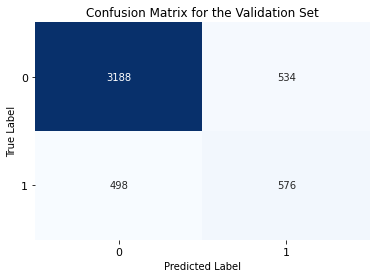

In [76]:
rfc_cf = confusion_matrix(y_val, rfc_grid_search.best_estimator_.predict(X_val))

con_mat_heatmap(rfc_cf, 'Validation')

Random forest precision-recall curve

In [77]:
# logisitc regression prediction probabilities
rfc_y_pred = rfc_grid_search.best_estimator_.predict_proba(X_val)[:,1]
# precision recall curve
rfc_prec, rfc_rec, _ = precision_recall_curve(y_val, rfc_y_pred)

AUC = 0.518


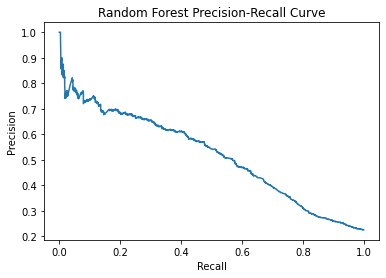

In [78]:
# precision recall curve plot
plt.plot(rfc_rec, rfc_prec)
# axis labels and title
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Random Forest Precision-Recall Curve')
# auc score
print(f'AUC = {round(auc(rfc_rec, rfc_prec),3)}')

## XGBClassifier

In [79]:
# xgb classifier pipeline with smote and xgb classifier model
xgbc_pipeline = Pipeline(steps = [['smote', SMOTE(random_state=11)],
                                ['xgbc', XGBClassifier(use_label_encoder=False, random_state=11, verbosity=0)]])
# stratified k fold
xgbc_stratified_kfold = StratifiedKFold(n_splits=10,
                                   shuffle=True,
                                   random_state=11)
# hyperparamater grid for key hyperparameters
# note that a number of parameters were inputed, optimal values were then selected afterwards and inputted 
# to avoid the long runtime   
xgbc_param_grid = {'xgbc__gamma': [5.5], 'xgbc__colsample_bytree': [0.8], 'xgbc__min_child_weight':[3], 
                   'xgbc__max_depth': [3], 'xgbc__reg_alpha': [0.9], 'xgbc__learning_rate': [0.02]}
# grid search cv to obtain optimal hyperparameters
xgbc_grid_search = GridSearchCV(estimator=xgbc_pipeline,
                           param_grid=xgbc_param_grid,
                           cv=xgbc_stratified_kfold,
                           return_train_score=True)
# fitting to the train data
xgbc_grid_search.fit(X_train, np.array(y_train))

GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=11, shuffle=True),
             estimator=Pipeline(steps=[['smote', SMOTE(random_state=11)],
                                       ['xgbc',
                                        XGBClassifier(base_score=None,
                                                      booster=None,
                                                      colsample_bylevel=None,
                                                      colsample_bynode=None,
                                                      colsample_bytree=None,
                                                      enable_categorical=False,
                                                      gamma=None, gpu_id=None,
                                                      importance_type=None,
                                                      interaction_constraints=None,
                                                      l...
                                                    

Best XGB classifier hyperparameters:

In [80]:
print(xgbc_grid_search.best_estimator_.get_params()['xgbc'])

XGBClassifier(base_score=0.5, booster='gbtree', colsample_bylevel=1,
              colsample_bynode=1, colsample_bytree=0.8,
              enable_categorical=False, gamma=5.5, gpu_id=-1,
              importance_type=None, interaction_constraints='',
              learning_rate=0.02, max_delta_step=0, max_depth=3,
              min_child_weight=3, missing=nan, monotone_constraints='()',
              n_estimators=100, n_jobs=8, num_parallel_tree=1, predictor='auto',
              random_state=11, reg_alpha=0.9, reg_lambda=1, scale_pos_weight=1,
              subsample=1, tree_method='exact', use_label_encoder=False,
              validate_parameters=1, verbosity=0)


XGB classifier learning curve:

<module 'matplotlib.pyplot' from 'c:\\python38\\lib\\site-packages\\matplotlib\\pyplot.py'>

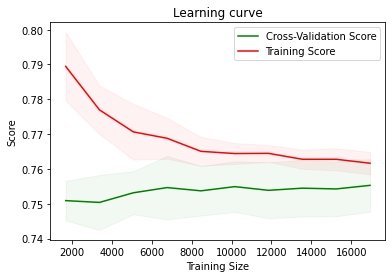

In [81]:
plot_learning_curve(X_train, np.ravel(y_train), xgbc_grid_search.best_estimator_.get_params()['xgbc'], 
                     xgbc_stratified_kfold, np.linspace(0.1, 1.0, 10))

XGB classifier classification report:

In [82]:
print(classification_report(y_val, xgbc_grid_search.best_estimator_.predict(X_val)))

              precision    recall  f1-score   support

           0       0.87      0.85      0.86      3722
           1       0.51      0.54      0.53      1074

    accuracy                           0.78      4796
   macro avg       0.69      0.70      0.69      4796
weighted avg       0.79      0.78      0.78      4796



XGB classifier confusion matrix:

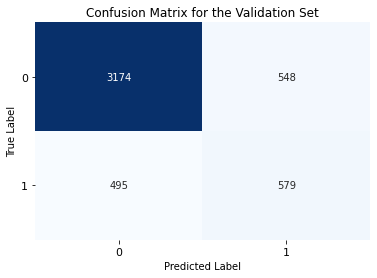

In [83]:
xgbc_cf = confusion_matrix(y_val, xgbc_grid_search.best_estimator_.predict(X_val))

con_mat_heatmap(xgbc_cf, 'Validation')

XGB classifier precision-recall curve

In [84]:
# XGB classifier prediction probabilities
xgbc_y_pred = xgbc_grid_search.best_estimator_.predict_proba(X_val)[:,1]
# precision recall curve
xgbc_prec, xgbc_rec, _ = precision_recall_curve(y_val, xgbc_y_pred)

AUC = 0.522


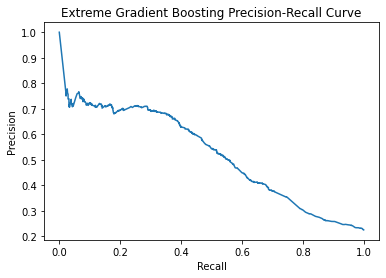

In [85]:
# precision recall curve plot
plt.plot(xgbc_rec, xgbc_prec)
# axis labels and title
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Extreme Gradient Boosting Precision-Recall Curve')
# auc score
print(f'AUC = {round(auc(xgbc_rec, xgbc_prec),3)}')

## Graph Compilation

### Learning Curve

The below cell combines all three learning curves into 1 plot, for ease of comparison, it is commented out to reduce runtime

In [86]:
# # best models from logistic regression, random forest and XGB classifier
# model = [lr_grid_search.best_estimator_.get_params()['lr'], rfc_grid_search.best_estimator_.get_params()['rfc'],
#         xgbc_grid_search.best_estimator_.get_params()['xgbc']]
# # cross validation
# cv_list = [lr_stratified_kfold, rfc_stratified_kfold, xgbc_stratified_kfold]
# # model names
# names = ['Logistic Regression', 'Random Forest', 'Extreme Gradient Boosting']
# # plot counter
# pos = 0
# # train size
# train_sizes = np.linspace(0.1, 1.0, 10)
# # train variables
# train_X = X_train
# # output variable
# train_y = np.ravel(y_train)
# # figure setup
# fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(16,4))
# # for loop to plot all learning curves
# for class_model, cv in zip(model, cv_list):
#     # learning curve
#     train_size, train_score, val_score = learning_curve(class_model, train_X, train_y, train_sizes=train_sizes, cv=cv, random_state=11, scoring='roc_auc',
#                                                         shuffle=True)
#     # mean and standard for the validation set
#     std_val_score = np.std(val_score, axis=1)
#     mean_val_score = np.mean(val_score, axis=1)
#     # mean and standard for the train set
#     std_train_score  = np.std(train_score, axis=1)
#     mean_train_score = np.mean(train_score, axis=1)
#     # plotting the standard deviation for the validation set
#     axs[pos].fill_between(x=train_size, y1=(mean_val_score - std_val_score), y2=(mean_val_score + std_val_score), color='green', alpha=0.05, )
#     # plotting the standard deviation for the train set
#     axs[pos].fill_between(x=train_size, y1=(mean_train_score - std_train_score), y2=(mean_train_score + std_train_score), color='red', alpha=0.05)

#     # validation plot
#     axs[pos].plot(train_size, mean_val_score, color='green', label='Cross-Validation Score')
#     # train plot
#     axs[pos].plot(train_size, mean_train_score, color='red', label='Training Score')
#     # axis labels and title
#     axs[pos].set_ylabel('Score')
#     axs[pos].set_xlabel('Training Size')
#     axs[pos].set_title(f'{names[pos]} Learning Curve')
#     # legend
#     axs[pos].legend(loc='best')
#     # updating plot position
#     pos+=1

### Confusion Matrices

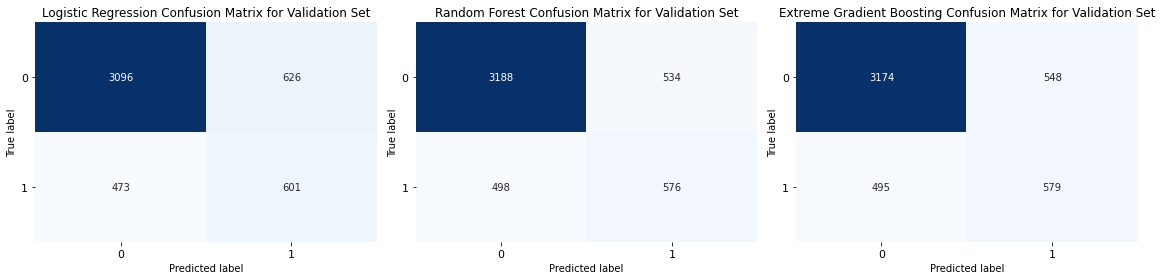

In [87]:
# zipping the confusion matrices and model names
cf = zip([lr_cf, rfc_cf, xgbc_cf], ['Logistic Regression', 'Random Forest', 'Extreme Gradient Boosting'])
# setting up the figure
fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(16,4))
# plot position
position = 0
# for loop for the plot
for i,j in cf:
    # confusion matrix being converted to pandas dataframe
    conf_mat = pd.DataFrame(i, index=[0,1], columns=[0,1])
    # heatmap of the confusion matrix
    heatmap = sns.heatmap(conf_mat, fmt='d', annot=True, cmap='Blues' ,ax=axs[position], cbar=False)
    # heat map axis labels
    heatmap.yaxis.set_ticklabels(heatmap.yaxis.get_ticklabels(), fontsize=11, rotation=360)
    heatmap.xaxis.set_ticklabels(heatmap.xaxis.get_ticklabels(), fontsize=11)
    # axis titles and plot title
    axs[position].set_ylabel('True label')
    axs[position].set_xlabel('Predicted label')
    axs[position].set_title(f'{j} Confusion Matrix for Validation Set')
    # updating the plot position
    position+=1
# adjusting the figure spacing
plt.tight_layout()

### Precision-Recall Curve

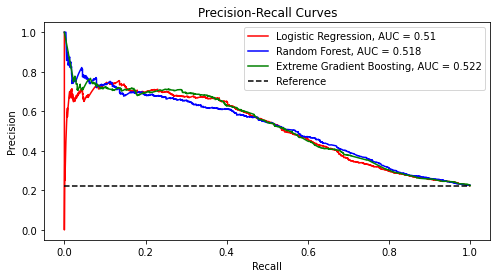

In [88]:
# figure set up
plt.figure(figsize=(8,4))
# logisitic regression precision-recall curve
plt.plot(lr_rec, lr_prec,'red', label=f'Logistic Regression, AUC = {round(auc(lr_rec, lr_prec),3)}')
# random forest precision-recall curve
plt.plot(rfc_rec, rfc_prec, 'blue', label=f'Random Forest, AUC = {round(auc(rfc_rec, rfc_prec),3)}')
# xgb classifier precision-recall curve
plt.plot(xgbc_rec, xgbc_prec, 'green', label=f'Extreme Gradient Boosting, AUC = {round(auc(xgbc_rec, xgbc_prec),3)}')
# reference line
ref = len(y_val[y_val==1]) / len(y_val)
# reference line plot
plt.plot([0, 1], [ref, ref], 'k--', label='Reference')
# axis labels and title
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves')
# legend
plt.legend()

# Further Tuning for Selected Model

## Feature Performance

To further improve the selected logisitic regression model, the feature coefficients for can be assessed

In [89]:
# best logisitic regression model
lr_best_feat = lr_grid_search.best_estimator_['lr']

Text(0.5, 1.0, 'Logisitic Regression Feature Importance')

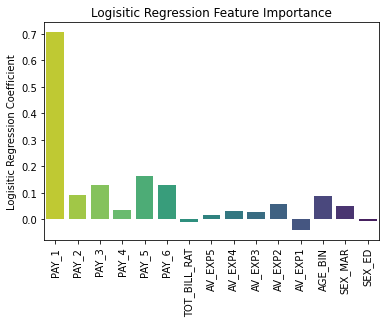

In [90]:
# plot of features against logistic regression coefficients
sns.barplot(x=(pd.DataFrame(model_data.drop(['DEF'], axis=1)).columns), y=lr_best_feat.coef_.flatten(), palette='viridis_r')
# axis labels and title
plt.xticks(rotation = 90)
plt.ylabel('Logisitic Regression Coefficient')
plt.title('Logisitic Regression Feature Importance')

- The TOT_BILL_RAT, SEX_ED, AV_EXP5 can be dropped due to their coefficients being extremely close to 0.
- Dropping these features may help to improve model performance as the data would be less ambiguos and decreases the possibility of over-fitting while having the added benefit of reduces training time.

In [91]:
new_model_data = model_data.drop(['SEX_ED', 'AV_EXP5', 'TOT_BILL_RAT'], axis=1)

## Re-training on the new data

In [92]:
# input variables
X = new_model_data.drop(['DEF'], axis=1)
# output variable
y = new_model_data['DEF']
# splitting into train and validation set
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=101)

# appyling the standard scalar
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_val = sc.transform(X_val)

# isolation forest
isolation_forest = IsolationForest(random_state=11)
iso_for_outliers = isolation_forest.fit_predict(X_train)
# local outlier factor
local_outf = LocalOutlierFactor(n_neighbors=5)
local_outf_outliers = local_outf.fit_predict(X_train)
# identifying the outliers
n_iso_for_outliers = len(np.where(iso_for_outliers == -1)[0])
n_local_outf_outliers = len(np.where(local_outf_outliers == -1)[0])
# identifying the common outliers
common = (iso_for_outliers == -1)&(local_outf_outliers == -1)
n_common = np.sum(common)
# Deleting the common outliers
X_train = pd.DataFrame(X_train)
X_train_ = X_train.drop(X_train[common].index)
# pandas dataframe to mupy array
X_train_ = X_train_.to_numpy()
# y train for the corresponding x train 
y_train.reset_index(drop=True, inplace=True)
y_train = pd.DataFrame(y_train)
y_train_ = y_train.drop(X_train[common].index)
# x train
X_train = X_train_
# y train
y_train = y_train_

In [93]:
# logistic regression pipeline
lr_pipeline = Pipeline(steps = [['smote', SMOTE(random_state=11)],
                                   ['lr', LogisticRegression(random_state=11)]])
# stratified k fold
lr_stratified_kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=11)
# hyperparameter grid - same as before    
lr_param_grid = {'lr__C':[0.1], 'lr__solver': ['saga'], 'lr__max_iter': [1000]}
# grid search cv for optimal hyperparameters
lr_grid_search = GridSearchCV(estimator=lr_pipeline,
                           param_grid=lr_param_grid,
                           cv=lr_stratified_kfold,
                           return_train_score=True)
# applying the model to the training data
lr_grid_search.fit(X_train, np.array(y_train))

GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=11, shuffle=True),
             estimator=Pipeline(steps=[['smote', SMOTE(random_state=11)],
                                       ['lr',
                                        LogisticRegression(random_state=11)]]),
             param_grid={'lr__C': [0.1], 'lr__max_iter': [1000],
                         'lr__solver': ['saga']},
             return_train_score=True)

Learning curve for the retuned logistic regression model

<module 'matplotlib.pyplot' from 'c:\\python38\\lib\\site-packages\\matplotlib\\pyplot.py'>

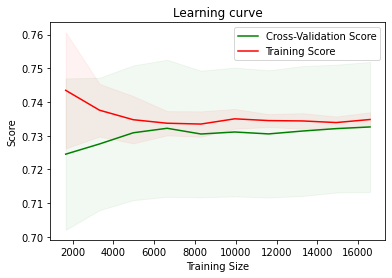

In [94]:
plot_learning_curve(X_train, np.ravel(y_train), lr_grid_search.best_estimator_.get_params()['lr'], 
                     lr_stratified_kfold, np.linspace(0.1, 1.0, 10))

Classification report for retuned logistic regression model:

In [95]:
print(classification_report(y_val, lr_grid_search.best_estimator_.predict(X_val)))

              precision    recall  f1-score   support

           0       0.87      0.83      0.85      3722
           1       0.49      0.57      0.53      1074

    accuracy                           0.77      4796
   macro avg       0.68      0.70      0.69      4796
weighted avg       0.78      0.77      0.78      4796



Confusion matrix for the retuned logistic regression model:

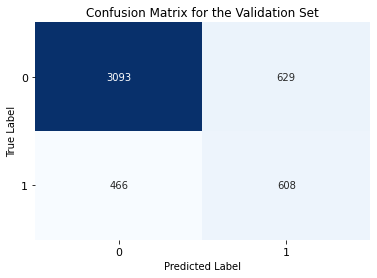

In [96]:
lr_cf = confusion_matrix(y_val, lr_grid_search.best_estimator_.predict(X_val))

con_mat_heatmap(lr_cf, 'Validation')

# Test Data

In [97]:
# calling the test data
test_data.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,24001,50000,1,2,2,23,2,2,0,0,...,44116,21247,20066,8,2401,2254,2004,704,707,0
1,24002,60000,1,2,2,26,0,0,0,0,...,55736,26958,28847,2282,2324,2049,2000,3000,1120,1
2,24003,400000,1,2,2,27,0,0,0,0,...,10745,20737,9545,2501,10009,1437,1105,510,959,0
3,24004,20000,1,5,2,27,5,4,3,2,...,19709,20113,19840,0,0,0,900,0,0,0
4,24005,50000,1,3,2,27,0,0,-2,-2,...,0,70,120,0,100,0,70,200,100,0


Checking for any NaNs as well as that the dtype is consistent with the train set

In [98]:
test_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          6000 non-null   int64
 1   LIMIT_BAL                   6000 non-null   int64
 2   SEX                         6000 non-null   int64
 3   EDUCATION                   6000 non-null   int64
 4   MARRIAGE                    6000 non-null   int64
 5   AGE                         6000 non-null   int64
 6   PAY_0                       6000 non-null   int64
 7   PAY_2                       6000 non-null   int64
 8   PAY_3                       6000 non-null   int64
 9   PAY_4                       6000 non-null   int64
 10  PAY_5                       6000 non-null   int64
 11  PAY_6                       6000 non-null   int64
 12  BILL_AMT1                   6000 non-null   int64
 13  BILL_AMT2                   6000 non-null   int64
 14  BILL_AMT

## Applying Transformations

Reassigning default column name:

In [99]:
test_data.rename(columns={'default payment next month':'DEF'}, inplace=True)

Renaming PAY_0 to PAY_1:

In [100]:
test_data.rename(columns={'PAY_0':'PAY_1'}, inplace=True)

Assigning education values 0, 5 and 6 to 4 (other catergory):

In [101]:
test_data['EDUCATION'].replace({0:4, 5:4, 6:4}, inplace=True)

Assigning the 0 in marraige to 3 (other catergory):

In [102]:
test_data['MARRIAGE'].replace({0:3}, inplace=True)

Assigning the -1 and -2 in PAY_# to 0:

In [103]:
for i in ['PAY_1','PAY_2','PAY_3','PAY_4','PAY_5', 'PAY_6']:
    test_data.replace({i:{-2:0, -1:0}}, inplace=True)

Average expenses:

In [104]:
#average expense 5
test_data['AV_EXP5'] = (test_data['BILL_AMT5'] - test_data['BILL_AMT6'] - test_data['PAY_AMT5']) / test_data['LIMIT_BAL']
#average expense 4
test_data['AV_EXP4'] = ((test_data['AV_EXP5'] + test_data['BILL_AMT4'] - test_data['BILL_AMT5'] - test_data['PAY_AMT4']) / 2) / test_data['LIMIT_BAL']
#average expense 3
test_data['AV_EXP3'] = ((test_data['AV_EXP4'] + test_data['BILL_AMT3'] - test_data['BILL_AMT4'] - test_data['PAY_AMT3']) / 3) / test_data['LIMIT_BAL']
#average expense 2
test_data['AV_EXP2'] = ((test_data['AV_EXP3'] + test_data['BILL_AMT2'] - test_data['BILL_AMT3'] - test_data['PAY_AMT2']) / 4) / test_data['LIMIT_BAL']
#average expense 1
test_data['AV_EXP1'] = (test_data['AV_EXP2'] + test_data['BILL_AMT1'] - test_data['BILL_AMT2'] - test_data['PAY_AMT1'] / 5) / test_data['LIMIT_BAL']

Binning age:

In [105]:
# bin splits
bins = [20, 25, 35, 45, 59, 100]
# names
bins_names = [5, 1, 2, 3, 4]
# creating the column
test_data['AGE_BIN'] = pd.cut(test_data['AGE'], bins, labels=bins_names)

SEX and MARRIAGE column:

In [106]:
# creating the sex and marriage column
test_data['SEX_MAR'] = 0
# married man
test_data.loc[((test_data['SEX'] == 1) & (test_data['MARRIAGE'] == 1)) , 'SEX_MAR'] = 4
# single man
test_data.loc[((test_data['SEX'] == 1) & (test_data['MARRIAGE'] == 2)) , 'SEX_MAR'] = 5 
# other man
test_data.loc[((test_data['SEX'] == 1) & (test_data['MARRIAGE'] == 3)) , 'SEX_MAR'] = 6
# married woman
test_data.loc[((test_data['SEX'] == 2) & (test_data['MARRIAGE'] == 1)) , 'SEX_MAR'] = 2
# single woman
test_data.loc[((test_data['SEX'] == 2) & (test_data['MARRIAGE'] == 2)) , 'SEX_MAR'] = 1
# other woman
test_data.loc[((test_data['SEX'] == 2) & (test_data['MARRIAGE'] == 3)) , 'SEX_MAR'] = 3 

Dropping the columns not required:

In [107]:
test_data.drop(['ID','BILL_AMT1', 'BILL_AMT2','BILL_AMT3', 'BILL_AMT4','BILL_AMT5','BILL_AMT6',
                'LIMIT_BAL','EDUCATION','PAY_AMT1','PAY_AMT2','PAY_AMT3', 'PAY_AMT4','PAY_AMT5', 'PAY_AMT6',
                'AGE','SEX','MARRIAGE', 'AV_EXP5'],axis=1, inplace=True)

## Applying the Model

In [108]:
# input variables
X = test_data.drop(['DEF'], axis=1)
# output variable
y= test_data['DEF']

In [109]:
# scaling the data by applying the transform fuction to the test data (X)
X = sc.transform(X)

In [110]:
# applying the retuned logistic regression model the test data
y_test_pred = lr_grid_search.best_estimator_.predict(X)

## Results

Classification report for the test data:

In [111]:
print(classification_report(y, y_test_pred))

              precision    recall  f1-score   support

           0       0.88      0.85      0.86      4734
           1       0.50      0.56      0.53      1266

    accuracy                           0.79      6000
   macro avg       0.69      0.70      0.69      6000
weighted avg       0.80      0.79      0.79      6000



Confusion matrix for the test data:

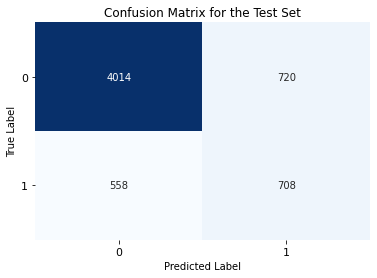

In [112]:
lr_cf = confusion_matrix(y, y_test_pred)

con_mat_heatmap(lr_cf, 'Test')